In [1]:
# Add the root path of the pyqula library
import os ; import sys
try: sys.path.append(os.environ["PYQULAROOT"]) # add the library via environmental variable
except: pass
try: from pyqula import geometry # check if the library is present
except: # pyqula not installed
    print("pyqula needs to be installed, installing it")
    import subprocess ; subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade","pyqula"])

# some default parameters in matplotlib
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [20, 8]
plt.rcParams['font.size'] = 22
plt.rcParams['image.cmap'] = 'coolwarm'


import numpy as np

# Advanced Quantum Materials, session 2: Band structure theory
Here we will first compute the electronic structure of different systems

### Contents
- Electronic structure of 2D and 1D systems
- Quadratic, Dirac electrons and flat bands
- Impact of interactions and symmetry breaking
- Impact of impurities

### Learning outcomes
- Understand how to rationalize the electronic structure of infinite 2D systems
- Understand the impact of electronic interactions in 2D materials featuring zero modes
- Rationalize the impact of interactions in electronic systems
- Understand how impurities can create resonant modes

### About the exercises
The notebooks contain two types of exercises, with each exercise containing **Quiz** questions to answer
- ***Core***: basic exercises you should understand in each session
- ***Challenge***: advanced exercises to dive deeper into concepts, not necessary to understand in full in each session  

## One dimensional chain (***Core***)
We will start with the structure and band structure of a one-dimensional chain

For a lattice with hoppings $t_n$ to the $n$-th neighbor, Bloch's theorem reduces the problem to a $1\times1$ Hamiltonian $H(k)=2\sum_n t_n\cos(nk)$, whose eigenvalue at each $k$ directly gives the band plotted next to the real-space unit cell.

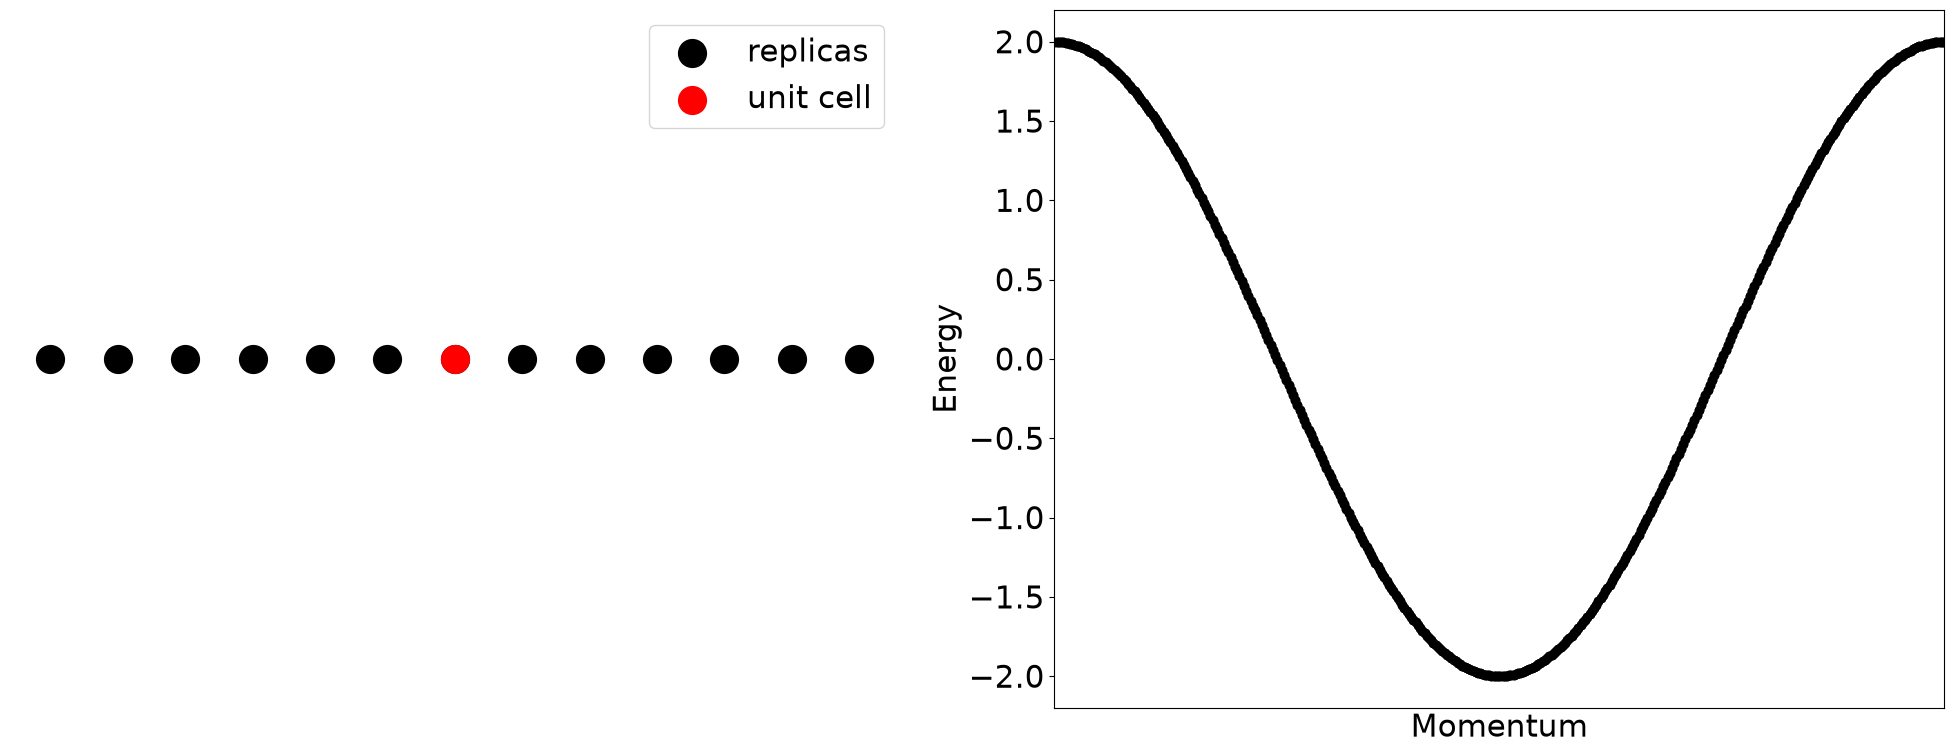

In [2]:
from pyqula import geometry
g = geometry.chain() # generate a chain


# function to plot the structure, we will reuse it afterwards
def plot_unit_cell(g,NS=3):
    """Function to plot the geometry of a model, NS is the size of the supercell"""
    gs = g.get_supercell(NS) # make a supercell and plot the structure
    r0 = g.r[0] # origin
    r0s = gs.r[len(g.r)*(NS//2)] # origin
    gs.set_origin(r0s) # set the origin in a site in the middle
    g.set_origin(r0) # set the origin in a site in the middle
    plt.scatter(gs.r[:,0],gs.r[:,1],c="black",s=400,label="replicas") ; plt.axis("equal") ; plt.axis("off") 
    plt.scatter(g.r[:,0],g.r[:,1],c="red",s=400,label="unit cell") ; plt.axis("equal") ; plt.axis("off") 
    plt.legend()

    
# now make the plots
plt.subplot(1,2,1)
plot_unit_cell(g,NS=13) # plot the structure

    
# plot the band structure
plt.subplot(1,2,2)
h = g.get_hamiltonian(tij=[1.0,0.]) # the argument tij are 1st, 2nd, 3rd nearest neighbor hoppings
(k,e) = h.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
plt.xticks([]) ; plt.xlim([min(k),max(k)])


plt.tight_layout()


### Exercise
- Identify the unit cell in the plot above
- What is the functional form of the band dispersion?
- How does the density of states look like?

## One dimensional chain, band folding (***Challenge***)
We can take more than one site per unit cell. In that situation, our band structure gets replicated

Doubling the unit cell halves the Brillouin zone and turns the single band $E(k)=2t\cos k$ into a $2\times2$ Bloch problem whose two eigenvalues are the same band folded back onto the smaller zone — the physics is unchanged, only the labeling by unit cell.

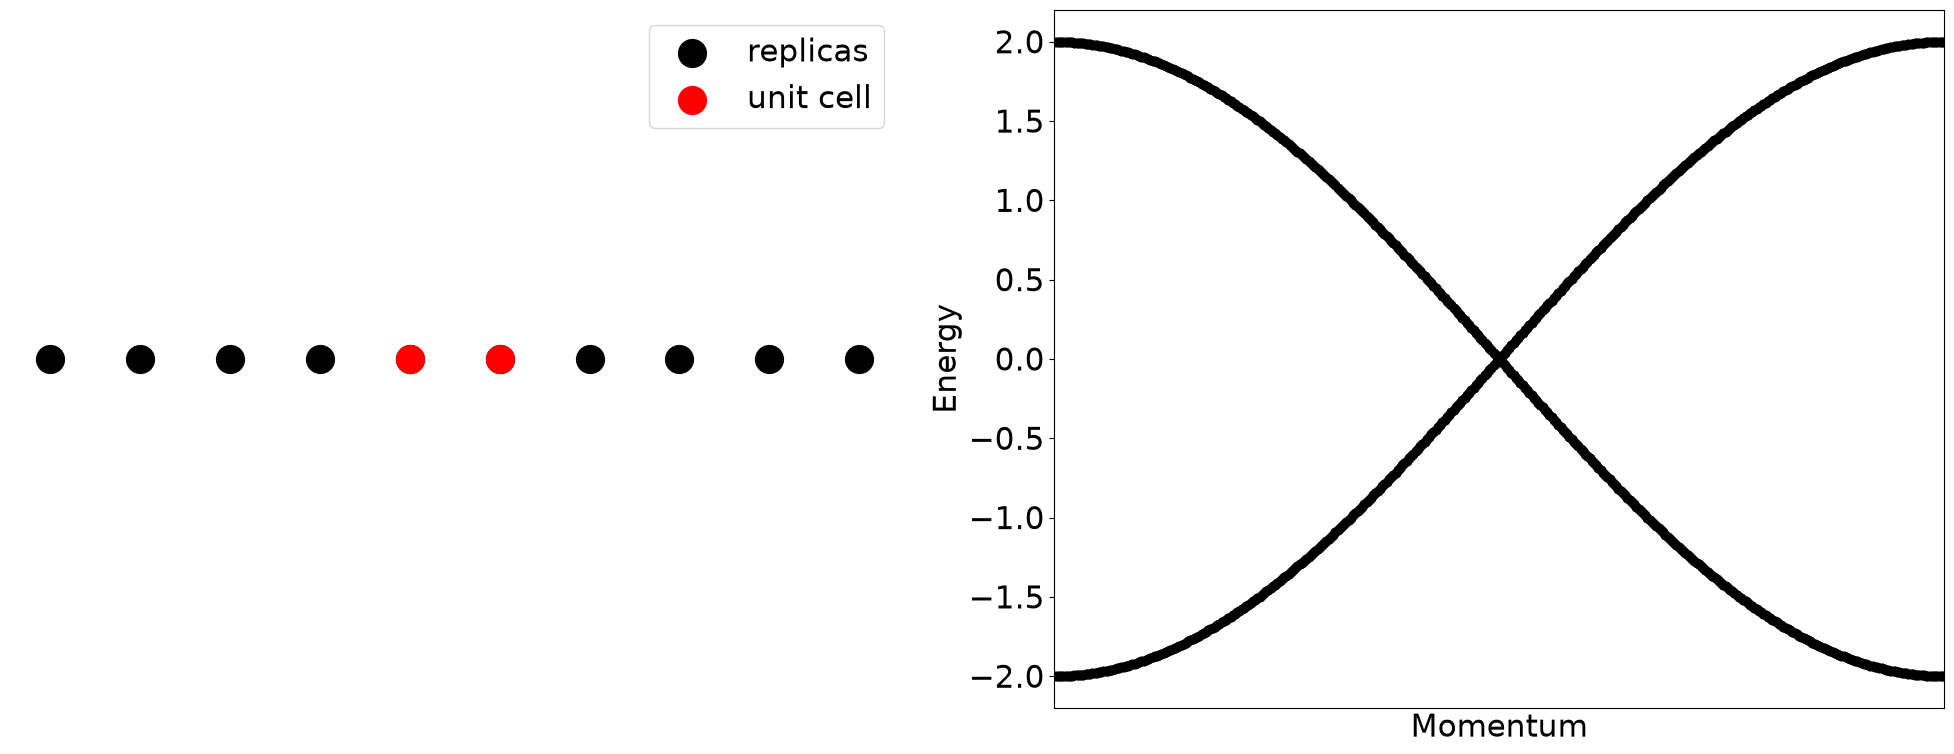

In [3]:
from pyqula import geometry
g = geometry.chain() # generate a chain
g = g.get_supercell(2) # make a supercell with 2 sites
# now make the plots
plt.subplot(1,2,1)
plot_unit_cell(g,NS=5) # plot the structure

    
# plot the band structure
plt.subplot(1,2,2)
h = g.get_hamiltonian(tij=[1.0]) # the argument tij are 1st, 2nd, 3rd nearest neighbor hoppings
(k,e) = h.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
plt.xticks([]) ; plt.xlim([min(k),max(k)])


plt.tight_layout()


### Exercise
- Write the Bloch Hamiltonian with two sites per unit cell
- Take a bigger unit cell. How is the band structure now and why?

# One dimensional ladder, band folding (***Challenge***)
We will now see how the band structure in ladders and ribbons emerge, and how they depend on the choice of unit cell

Choosing a supercell of $N$ primitive cells turns the Bloch Hamiltonian into an $N\times N$ matrix (times the number of orbitals per site, e.g. two for a ladder's rungs); its $N$ eigenvalues at each $k$ are the original band(s) folded onto the correspondingly smaller Brillouin zone $k\in(-\pi/N,\pi/N]$.

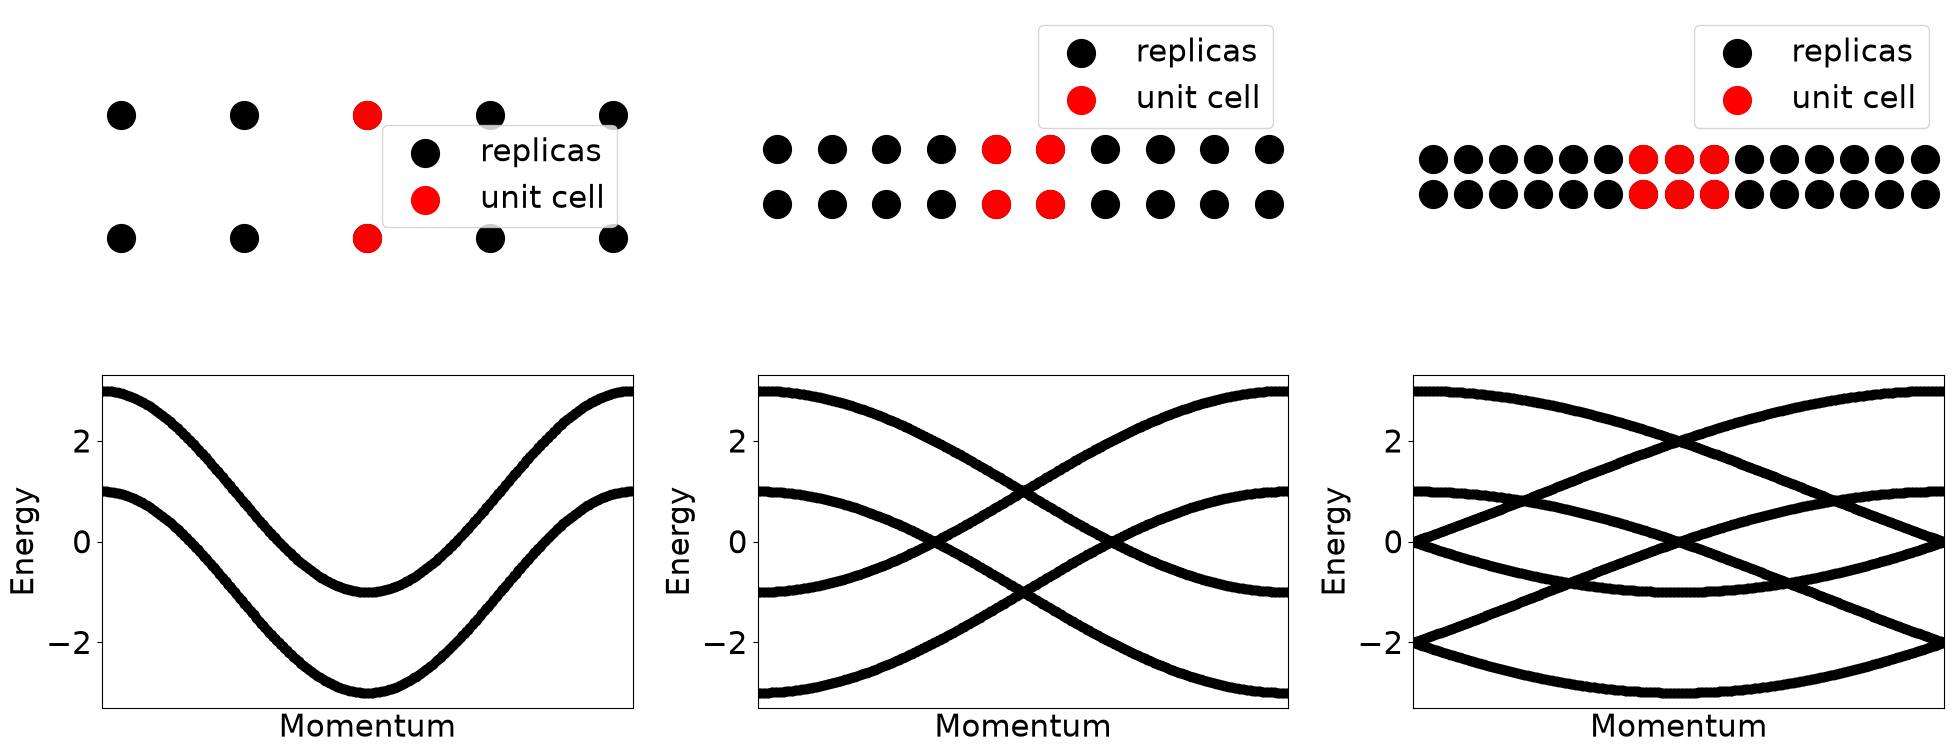

In [4]:
from pyqula import geometry
g0 = geometry.ladder() # generate a ladder
#g0 = geometry.square_ribbon(5) # generate a square ribbon
NSs = [1,2,3] # supercells to consider
iNS = 0 # counter
for NS in NSs: # loop over supercells
    iNS += 1 # increase counter
    g = g0.get_supercell(NS) # make a supercell with 2 sites
    plt.subplot(2,len(NSs),iNS) # structure
    plot_unit_cell(g,NS=5) # plot the structure

    plt.subplot(2,len(NSs),iNS + len(NSs)) # band structure
    h = g.get_hamiltonian(has_spin=False) # compute bands
    (k,e) = h.get_bands() # compute band structure
    plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
    plt.xticks([]) ; plt.xlim([min(k),max(k)])


plt.tight_layout()


### Exercise
- What is the dimension of the Bloch Hamiltonian in each case?
- Replace the ladder by a square ribbon. What is the dimension of the Bloch Hamiltonian in each case?

## One dimensional chain, with longer range hopping (***Core***)
 We will compute the band structure and density of states in the presence of longer range hopping

With hoppings up to third neighbors, $E(k) = 2t_1\cos k + 2t_2\cos 2k + 2t_3\cos 3k$. A nonzero $t_3$ adds extra curvature to the band, producing additional van Hove singularities in the density of states.

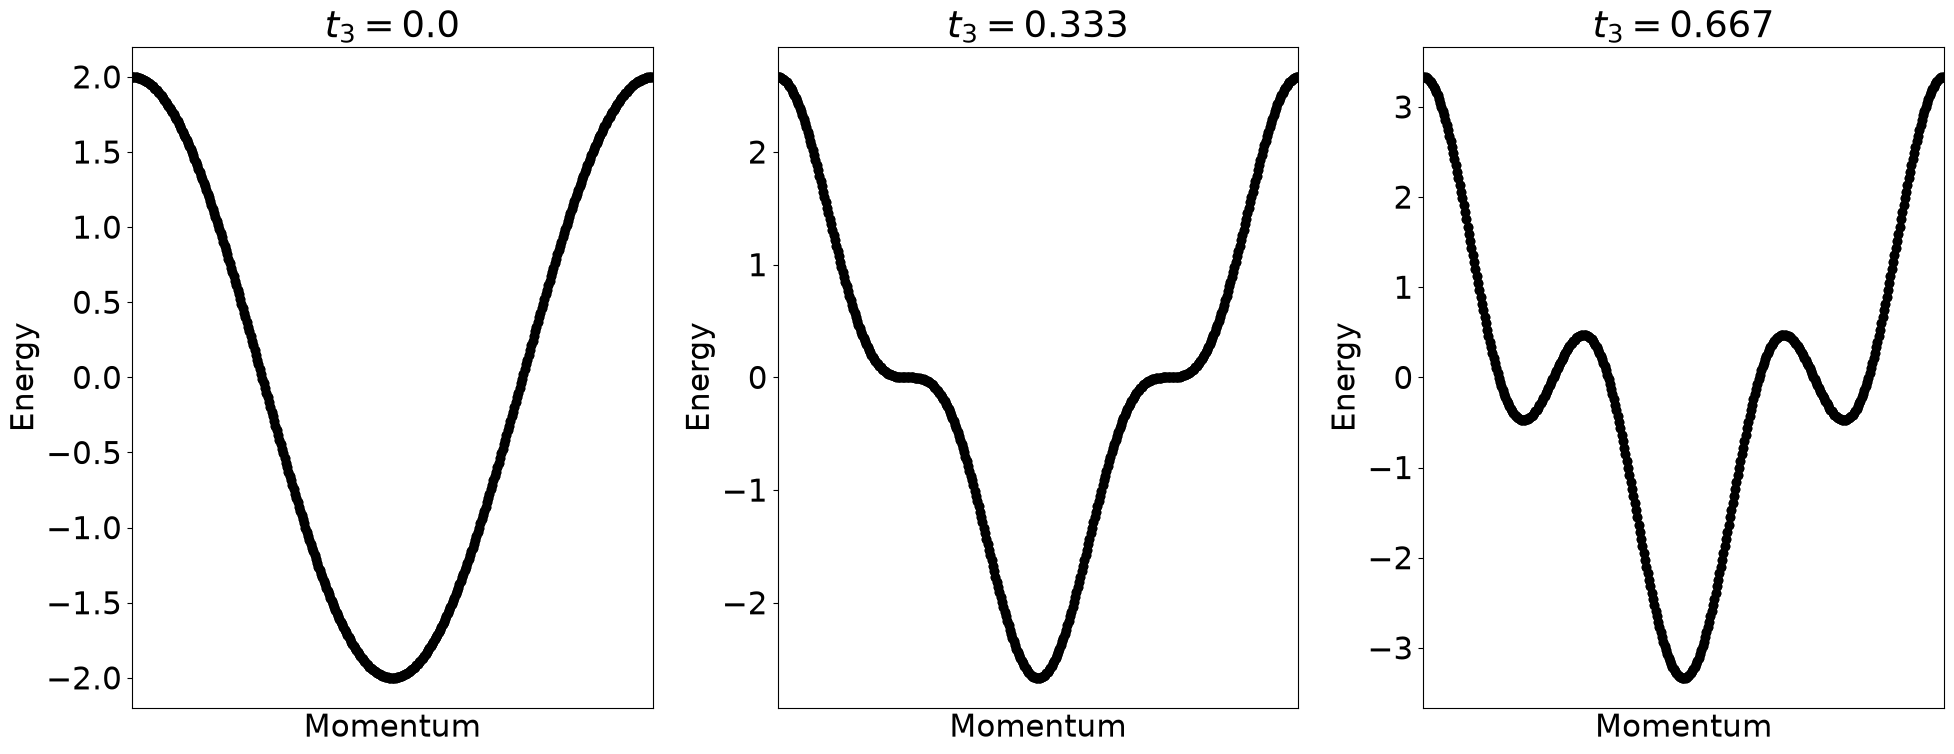

In [5]:
# first let us compute the band structure
from pyqula import geometry
g = geometry.chain() # generate a chain
t3s = [0.,1./3.,2./3.] # values for the third neighbor hopping
for i in range(len(t3s)): # loop over third neighbor hopping
    t3 = t3s[i] # get the value of the 3rd NN hopping
    h = g.get_hamiltonian(tij=[1.0,0.,t3]) # the argument tij are 1st, 2nd, 3rd nearest neighbor hoppings
    plt.subplot(1,len(t3s),i+1)
    (k,e) = h.get_bands() # compute band structure
    plt.title("$t_3 = $"+str(np.round(t3,3)))
    plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
    plt.xticks([]) ; plt.xlim([min(k),max(k)])

plt.tight_layout()

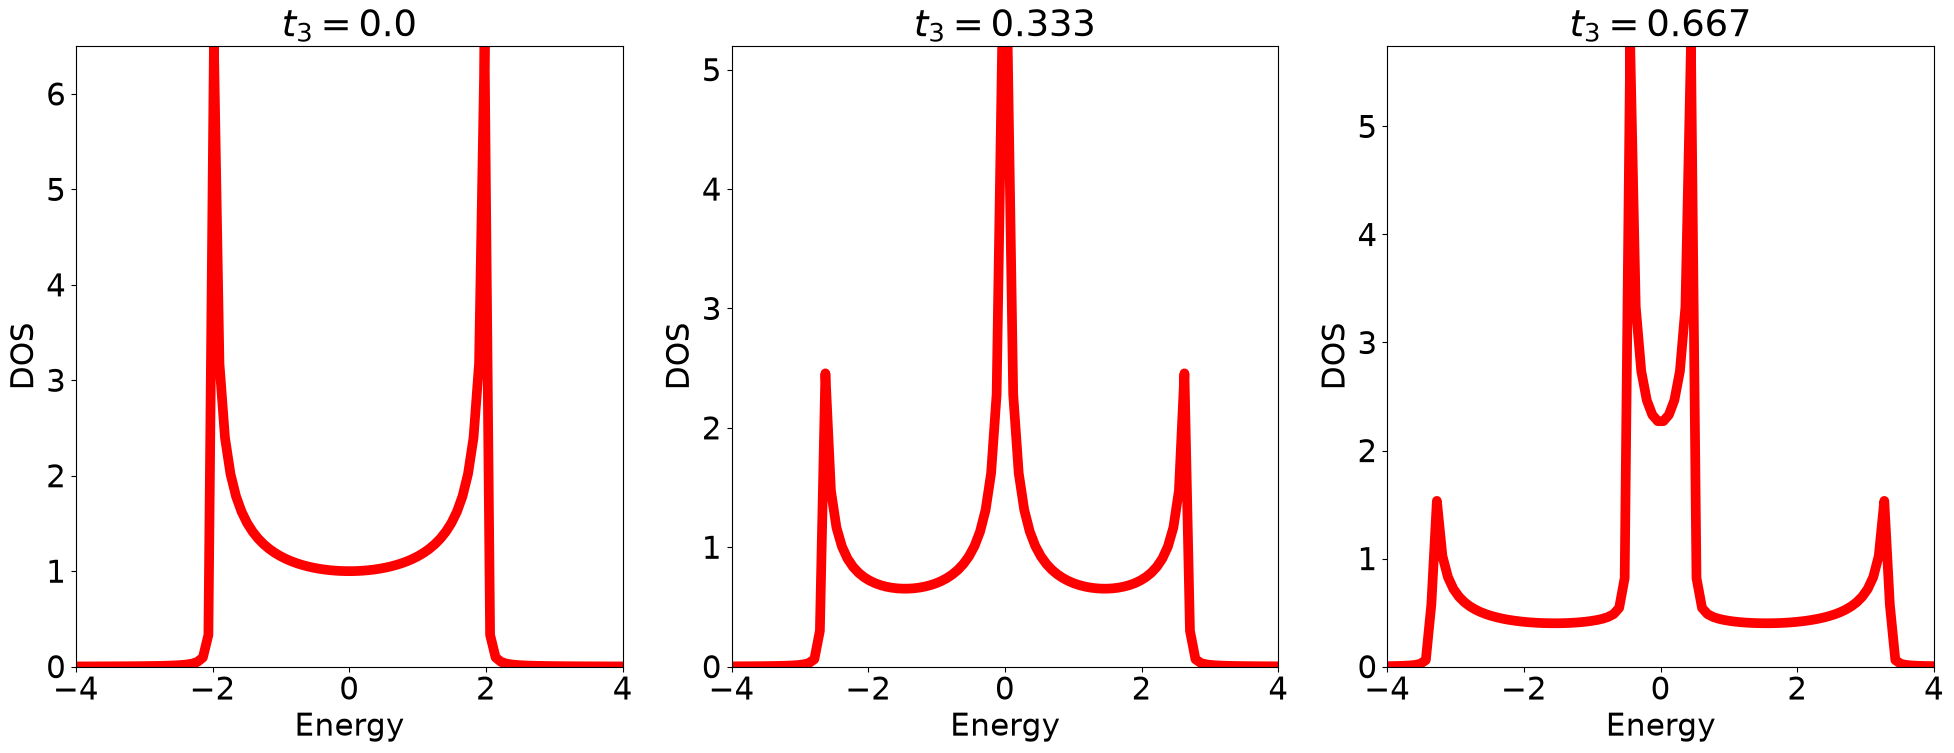

In [6]:
# now let us compute the density of states

from pyqula import geometry
g = geometry.chain() # generate a chain
t3s = [0.,1./3.,2./3.] # values for the third neighbor hopping
energies = np.linspace(-4.,4.,100) 
for i in range(len(t3s)): # loop over third neighbor hopping
    t3 = t3s[i] # get the value of the 3rd NN hopping
    h = g.get_hamiltonian(tij=[1.0,0.,t3]) # the argument tij are 1st, 2nd, 3rd nearest neighbor hoppings
    plt.subplot(1,len(t3s),i+1)
    (e,d) = h.get_dos(energies=energies,mode="Green",delta=1e-2) # compute DOS (using renormalization group)
    plt.title("$t_3 = $"+str(np.round(t3,3)))
    plt.plot(e,d,c="red",linewidth=7) ; plt.xlabel("Energy") ; plt.ylabel("DOS") 
    plt.ylim([0.,np.max(d)]) ; plt.xlim([np.min(energies),np.max(energies)])

plt.tight_layout()

### Exercise
- How is the divergent DOS related to the band structure?
- Why do you get a divergence at E=0 for t3=1/3?
- If instead of 3rd NN you add 2nd NN hopping, how does the band structure change?

## Infinite two-dimensional graphene (***Core***)
First, we will consider a two-dimensional honeycomb lattice that is infinite in both directions

The honeycomb lattice has two sites per unit cell, so the Bloch Hamiltonian is $2\times2$,
$$H(\mathbf k) = \begin{pmatrix} 0 & f(\mathbf k) \\ f^*(\mathbf k) & 0\end{pmatrix},\qquad f(\mathbf k)=t\sum_{i=1}^3 e^{i\mathbf k\cdot\boldsymbol\delta_i}$$
with eigenvalues $E_\pm(\mathbf k)=\pm|f(\mathbf k)|$. $f$ vanishes linearly at the corners $K,K'$ of the Brillouin zone, producing the massless Dirac cones responsible for graphene's vanishing density of states at $E=0$.

(0.0, 0.6696943587924159)

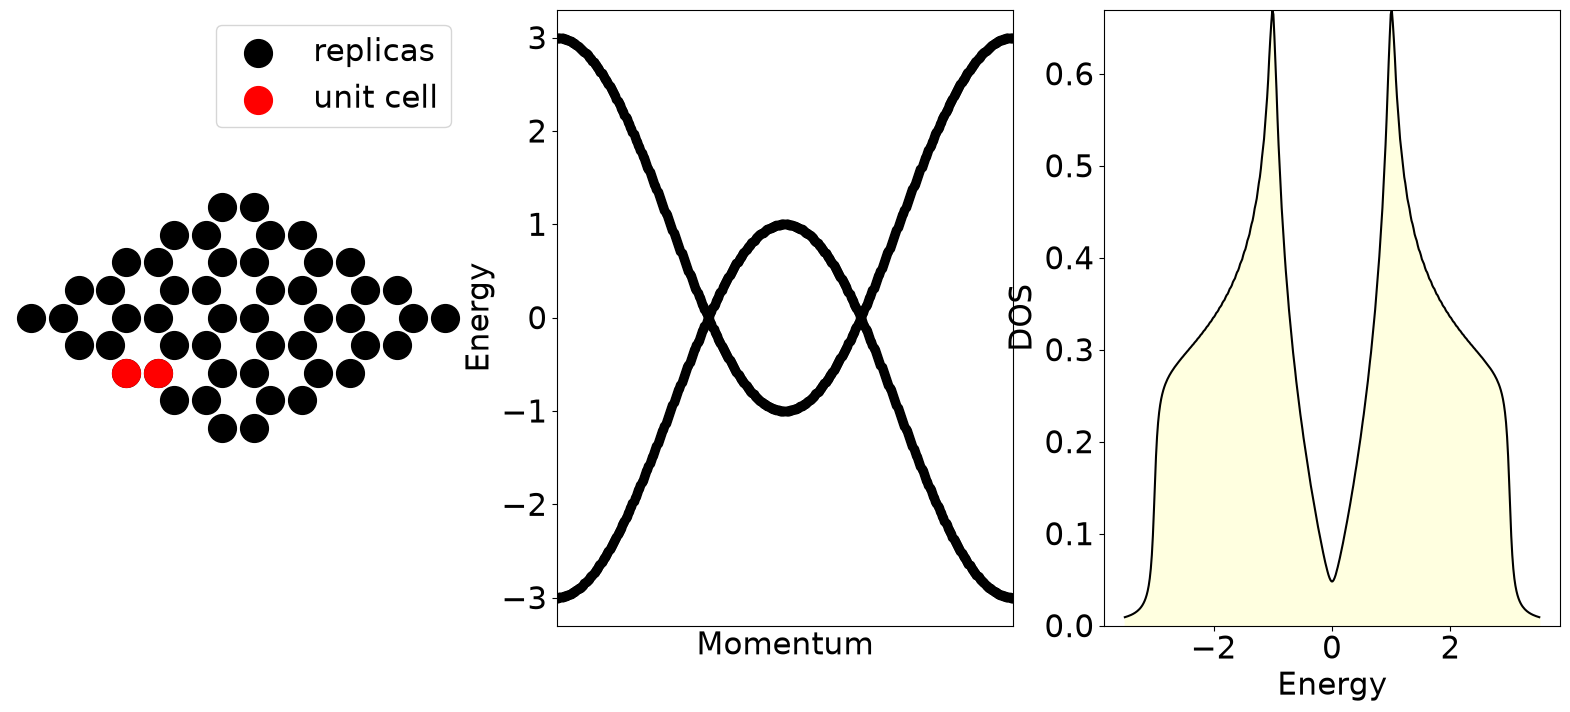

In [7]:
from pyqula import geometry
g = geometry.honeycomb_lattice() # generate a honeycomb lattice
#g = geometry.lieb_lattice() # generate a Lieb lattice
#g = geometry.kagome_lattice() # generate a kagome lattice
plt.subplot(1,3,1)
plot_unit_cell(g,NS=5) # plot the structure

# plot the band structure
plt.subplot(1,3,2)
h = g.get_hamiltonian(tij=[1.0],has_spin=False) # the argument tij are 1st, 2nd, 3rd nearest neighbor hoppings
(k,e) = h.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
plt.xticks([]) ; plt.xlim([min(k),max(k)])

plt.subplot(1,3,3)
(e,d) = h.get_dos(delta=5e-2,energies=np.linspace(-3.5,3.5,400)) # let us compute now the density of states
plt.plot(e,d,c="black") ; plt.xlabel("Energy") ; plt.ylabel("DOS") # plot
plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') # add a background
plt.ylim([0,max(d)])

### Exercise
- Identify the unit cell in the plot above
- Replace the honeycomb lattice by a kagome lattice and lieb. Identify the unit cell

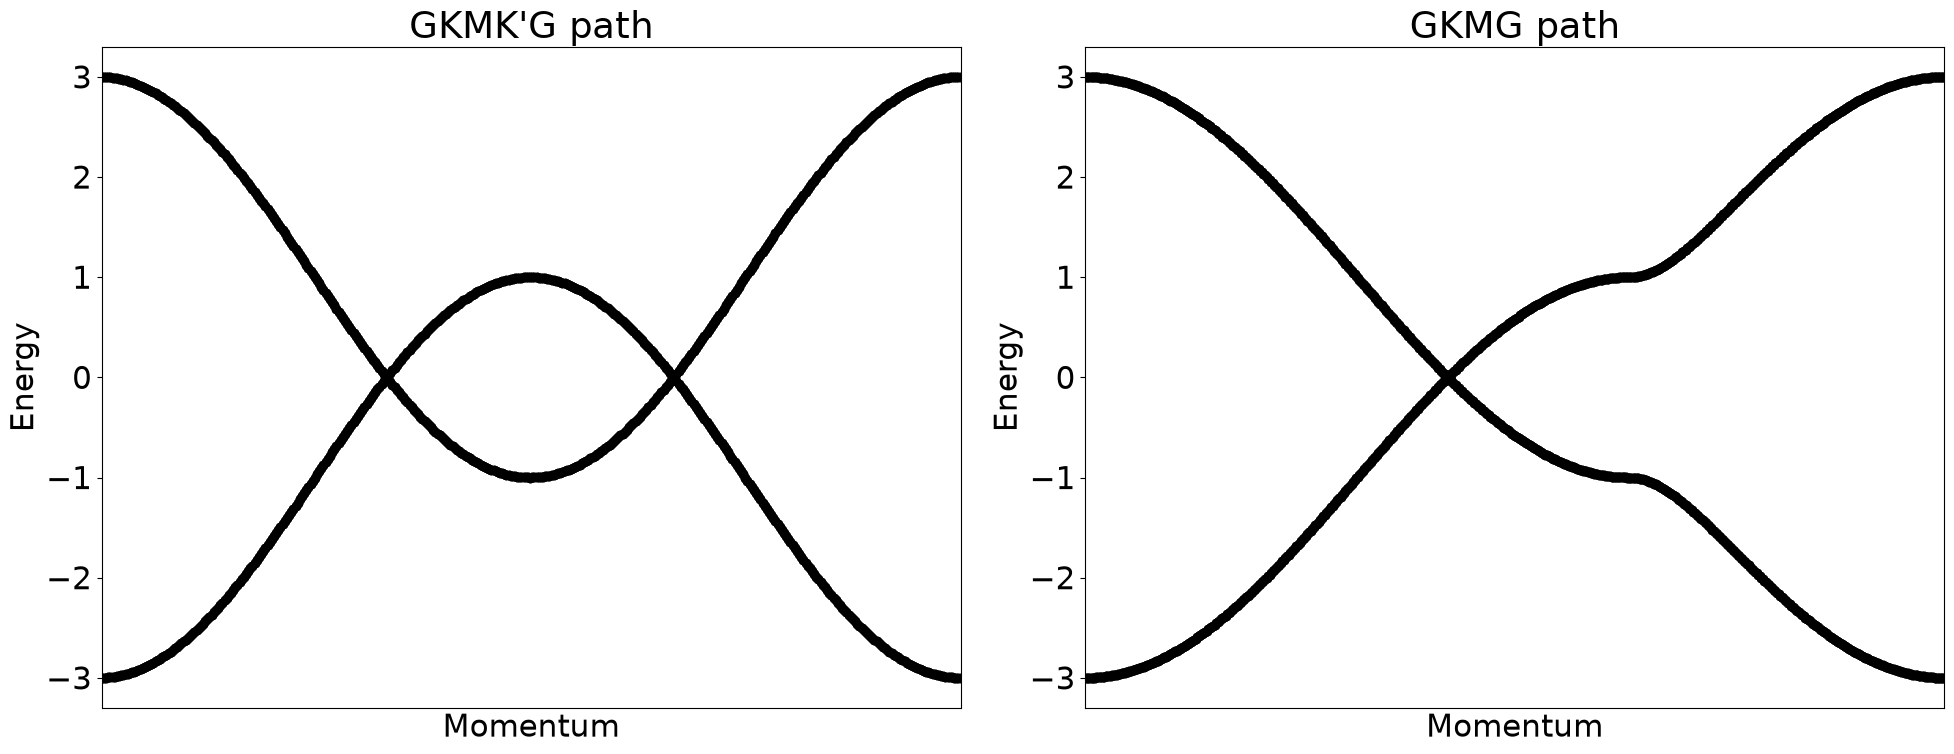

In [8]:
from pyqula import geometry
# now compute the band structure
plt.subplot(1,2,1) ; plt.title("GKMK'G path")
g = geometry.honeycomb_lattice() # generate a honeycomb lattice
h = g.get_hamiltonian() # generate the Hamiltonian
(k,e) = h.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
plt.xticks([]) ; plt.xlim([min(k),max(k)])

# we can also compute the band structure in a different kpath
plt.subplot(1,2,2) ; plt.title("GKMG path")
g = geometry.honeycomb_lattice() # generate a honeycomb lattice
h = g.get_hamiltonian() # generate the Hamiltonian
(k,e) = h.get_bands(kpath=["G","K","M","G"]) # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
plt.xticks([]) ; plt.xlim([min(k),max(k)])

plt.tight_layout()

### Exercise
- Identify the location of the Dirac point in the previous plots

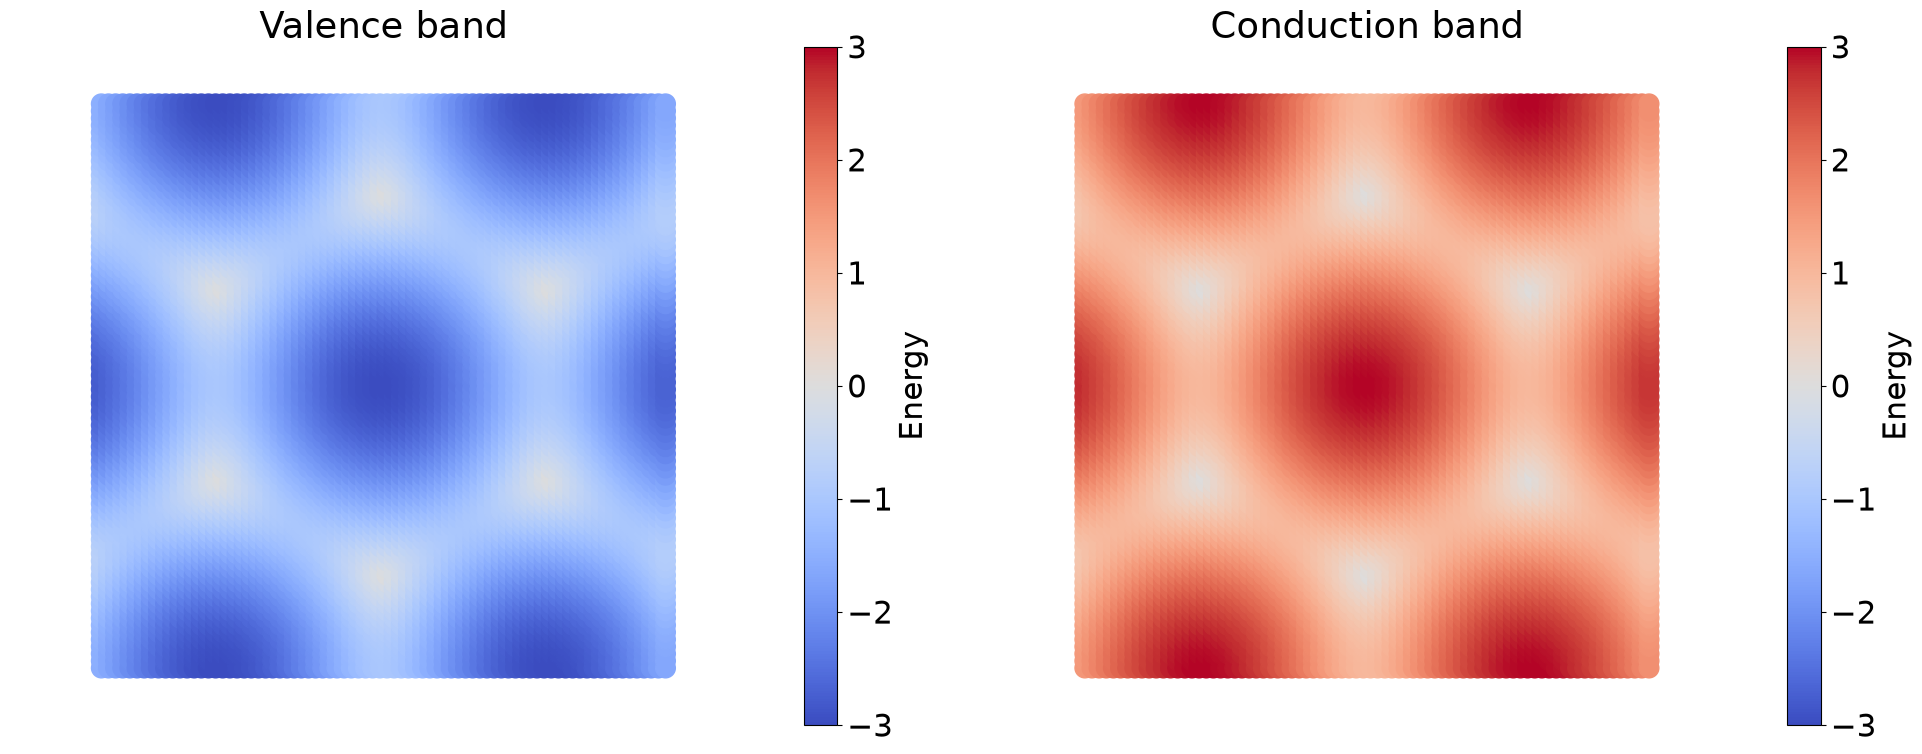

In [9]:
# we can also compute the band structure in the 2d Brillouin zone
from pyqula import geometry
g = geometry.honeycomb_lattice() # generate a honeycomb lattice
h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian

def plot_case(k,e):
    plt.scatter(k[:,0],k[:,1],c=e,s=200,cmap="coolwarm",vmin=-3,vmax=3) 
    plt.axis("off") ; plt.axis("equal") ; plt.colorbar(label="Energy")
    
# valence band state
(k,e) = h.get_bands_map(n=0,nk=80) 
plt.subplot(1,2,1) ; plt.title("Valence band")
plot_case(k,e)

# conduction band state
(k,e) = h.get_bands_map(n=1,nk=80) 
plt.subplot(1,2,2) ; plt.title("Conduction band")
plot_case(k,e)

plt.tight_layout()

### Exercise
- Identify the location of the Dirac point in the 2D bandstructure above
- Replace the honeycomb lattice by a Kagome lattice. What do you see in those maps and what does it imply?

## Fermi surface of the honeycomb lattice (***Challenge***)
Let us now see how to compute Fermi surface, focusing on the case of 2D graphene

The Fermi surface at energy $E$ is the constant-energy contour $\{\mathbf k: E(\mathbf k)=E\}$ of the band structure. Its topology changes — from small pockets around $K,K'$ to one connected contour — exactly at the van Hove energy, where the density of states diverges logarithmically.

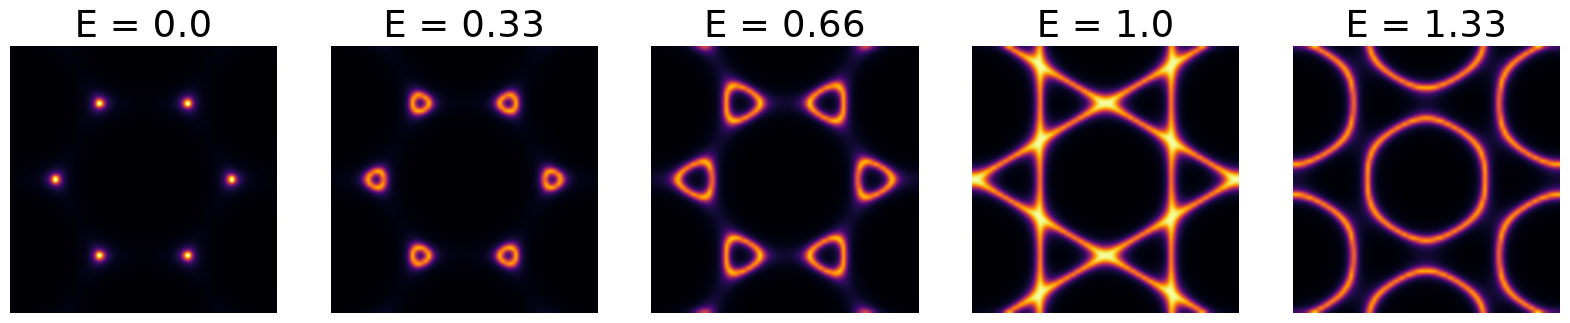

In [10]:
from pyqula import geometry
g = geometry.honeycomb_lattice() # generate a honeycomb lattice
#g = geometry.square_lattice() # generate a square lattice
h = g.get_hamiltonian() # generate the Hamiltonian
delta = 0.1 ; nk = 80 # smearing and kmesh
energies = np.linspace(0.,1.33,5,endpoint=True) # energies
ip = 1 # counter for the plot
for e in energies:
    (x,y,d) = h.get_fermi_surface(e=e,delta=delta,nk=nk) # compute Fermi surface
    plt.subplot(1,len(energies),ip) ; ip += 1 # set subplot
    d2d = d.reshape((nk,nk)) ; plt.imshow(d2d,vmin=0.,vmax=2./delta,cmap="inferno",interpolation="bicubic") 
    plt.title("E = "+str(np.round(e,2))) ; plt.axis("off")

### Quiz
- Identify at which energy the van Hove singularity appears
- Compute the Fermi surface at higher energies. How many pockets do you have after you pass the van Hove singularity?
- Replace the honeycomb lattice by a square lattice. How is the Fermi surface now?

## Density of states of the honeycomb lattice (***Core***)
Let us now see how to compute Fermi surface, focusing on the case of 2D graphene

The density of states $g(E)=\sum_{\mathbf k,n}\delta(E-E_n(\mathbf k))$ vanishes linearly, $g(E)\propto|E|$, near the Dirac point, and diverges logarithmically at the van Hove energy where the bands have a saddle point.

(0.0, 0.7007604237585386)

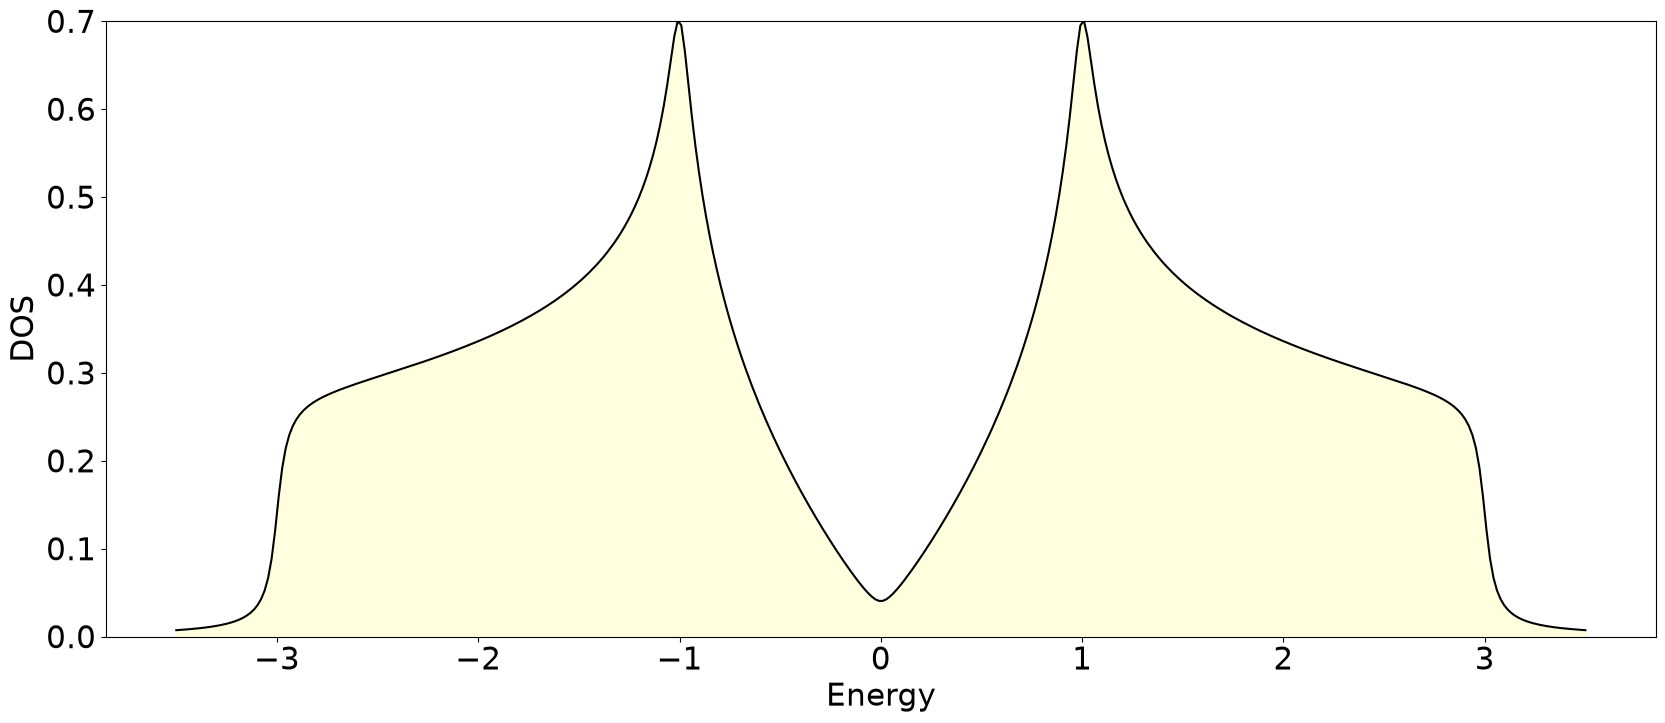

In [11]:
# we can also compute the total density of states
from pyqula import geometry
g = geometry.honeycomb_lattice() # generate a honeycomb lattice
#g = geometry.triangular_lattice() # generate a triangular lattice
h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
(e,d) = h.get_dos(delta=4e-2,energies=np.linspace(-3.5,3.5,400),nk=200) # let us compute now the density of states
plt.plot(e,d,c="black") ; plt.xlabel("Energy") ; plt.ylabel("DOS") # plot
plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') # add a background
plt.ylim([0,max(d)])

### Exercise
- Identify the location of the Dirac point in the density of states
- Identify the location of the van Hove singularity in the density of states
- Replace the honeycomb lattice by a triangular lattice. Do you still observe a Dirac point and van Hove singularities?

## Band structure of honeycomb nanoribbons (***Challenge***)
We now focus on considering nanoribbons, systems with a finite width and infinite in the x-direction

Confining the honeycomb lattice to a finite width $W$ (periodic only along one direction) turns the continuous 2D bands into $W$ discrete 1D subbands $E_n(k_x)$. Zigzag edges additionally support a flat band of edge states pinned near $E=0$ that has no counterpart in the bulk dispersion.

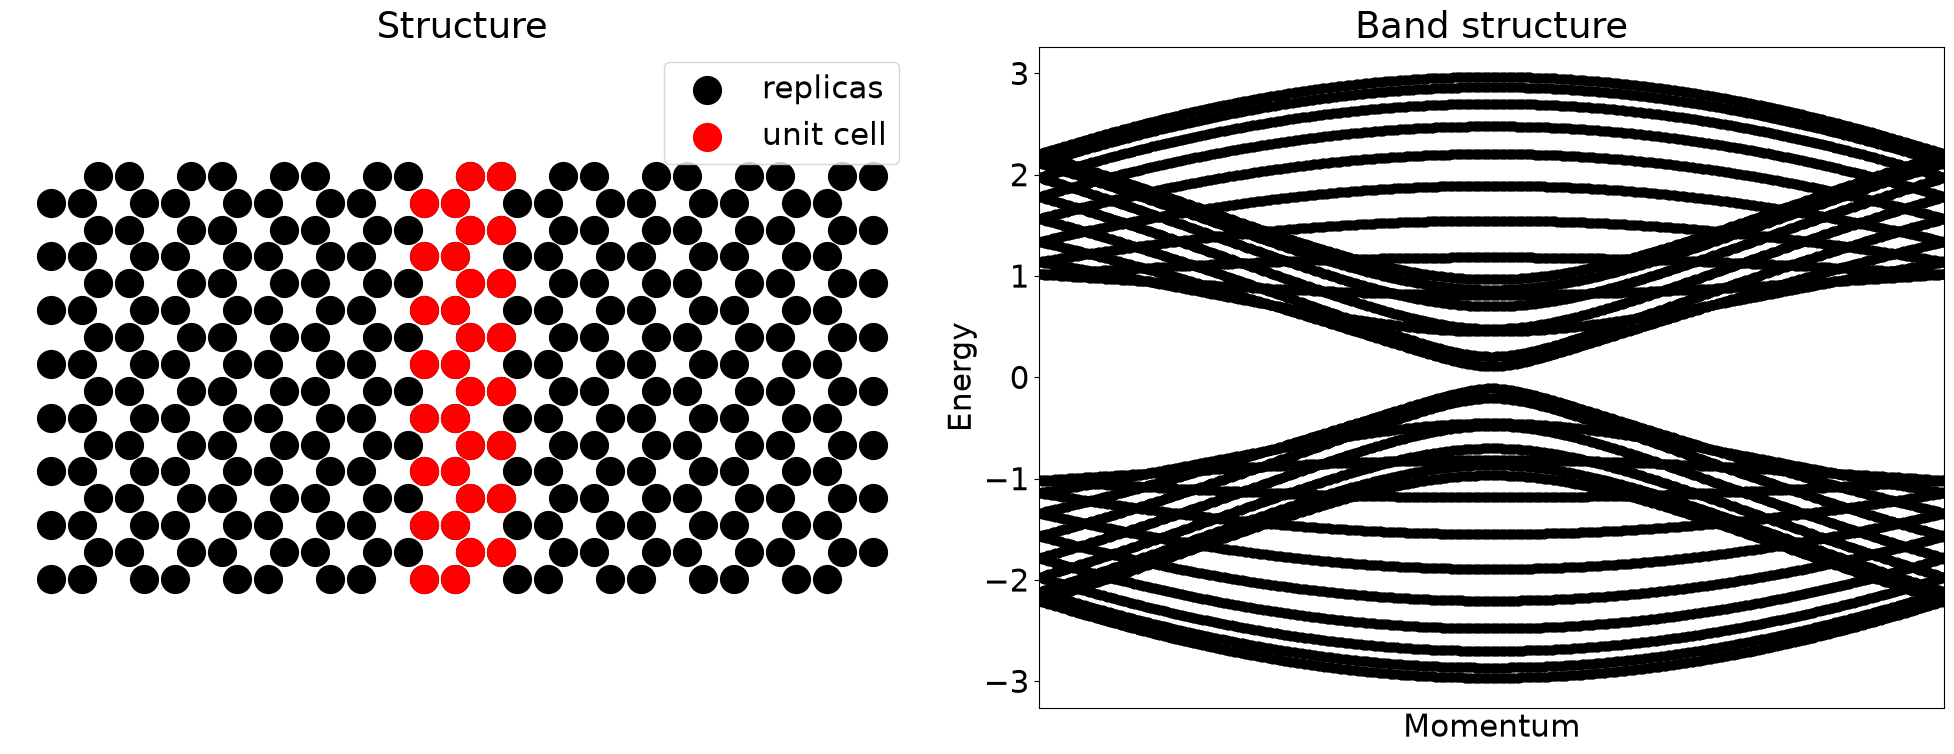

In [12]:
from pyqula import geometry
 
plt.subplot(1,2,1) ; plt.title("Structure")
g = geometry.honeycomb_armchair_ribbon(8) # generate a honeycomb armchair ribbon
#g = geometry.honeycomb_zigzag_ribbon(8) # generate a honeycomb zigzag ribbon
plot_unit_cell(g,NS=9) # plot the structure

plt.subplot(1,2,2) ; plt.title("Band structure")
h = g.get_hamiltonian() # generate the Hamiltonian
(k,e) = h.get_bands(kpath=["M","G","M"]) # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
plt.xticks([]) ; plt.xlim([min(k),max(k)])

plt.tight_layout()

### Exercise
- Discuss why there are now more bands than in the bulk calculations
- Change the width of the ribbon. What happens to the number of bands in the plot above, and why?
- Replace the armchair nanoribbon by a zigzag nanoribbon. Which important difference do you see in the bandstructure?

## Density of states of nanoribbons (***Challenge***)
Now we will compute the density of states of graphene nanoribbon, and see that it resembles the one of two dimensional graphene

Each 1D subband contributes its own $1/\sqrt{E-E_n}$ van Hove singularity to the ribbon's density of states; summing over the $W$ subbands reproduces, on average, the 2D graphene density of states found above.

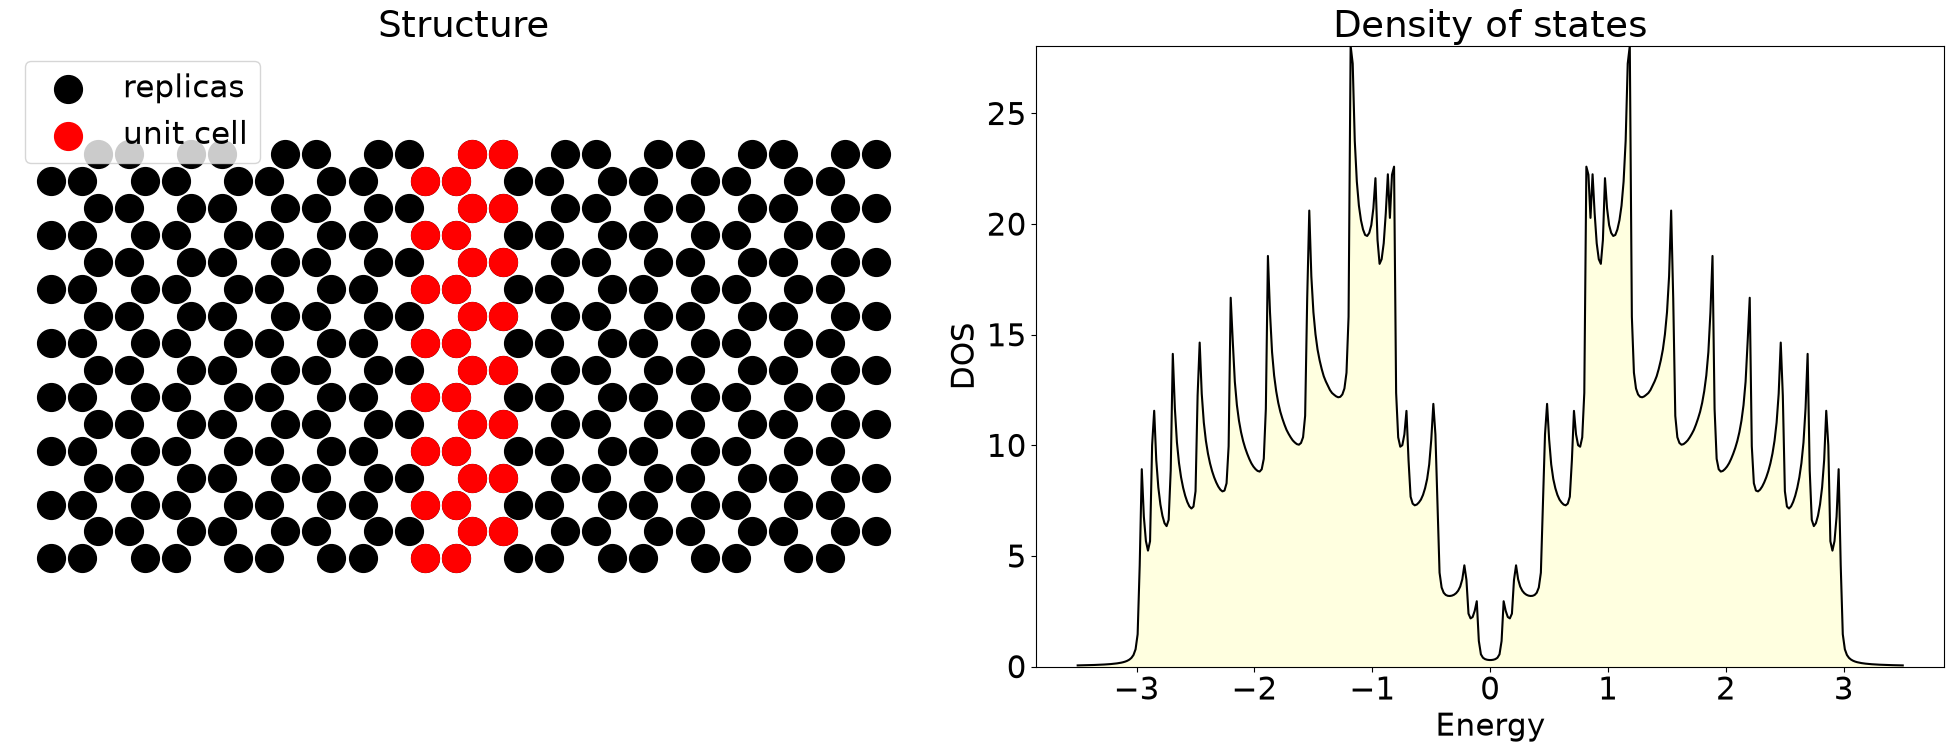

In [13]:
from pyqula import geometry
 
plt.subplot(1,2,1) ; plt.title("Structure")
g = geometry.honeycomb_armchair_ribbon(8) # generate a honeycomb ribbon with armchair edge
plot_unit_cell(g,NS=9) # plot the structure

plt.subplot(1,2,2) ; plt.title("Density of states")
h = g.get_hamiltonian() # generate the Hamiltonian
(e,d) = h.get_dos(delta=1e-2,energies=np.linspace(-3.5,3.5,400),nk=300) # let us compute now the density of states
plt.plot(e,d,c="black") ; plt.xlabel("Energy") ; plt.ylabel("DOS") # plot
plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') ; plt.ylim([0,max(d)]) # add a background

plt.tight_layout()

### Exercise
- Why are there several divergencies on the DOS?
- Change the width of the ribbon. How does the number of peaks change?

## Width dependence of the electronic structure in graphene nanoribbons (***Challenge***)
Let us now address how the electronic structure of graphene depends on the width of the nanoribbon

Quantum confinement along the width sets a gap $E_g\sim v_F\pi/W$ that shrinks as $1/W$ with increasing ribbon width $W$. For armchair edges the gap additionally depends on $W\bmod 3$, since only for specific widths does a confined transverse momentum land exactly on the Dirac point.

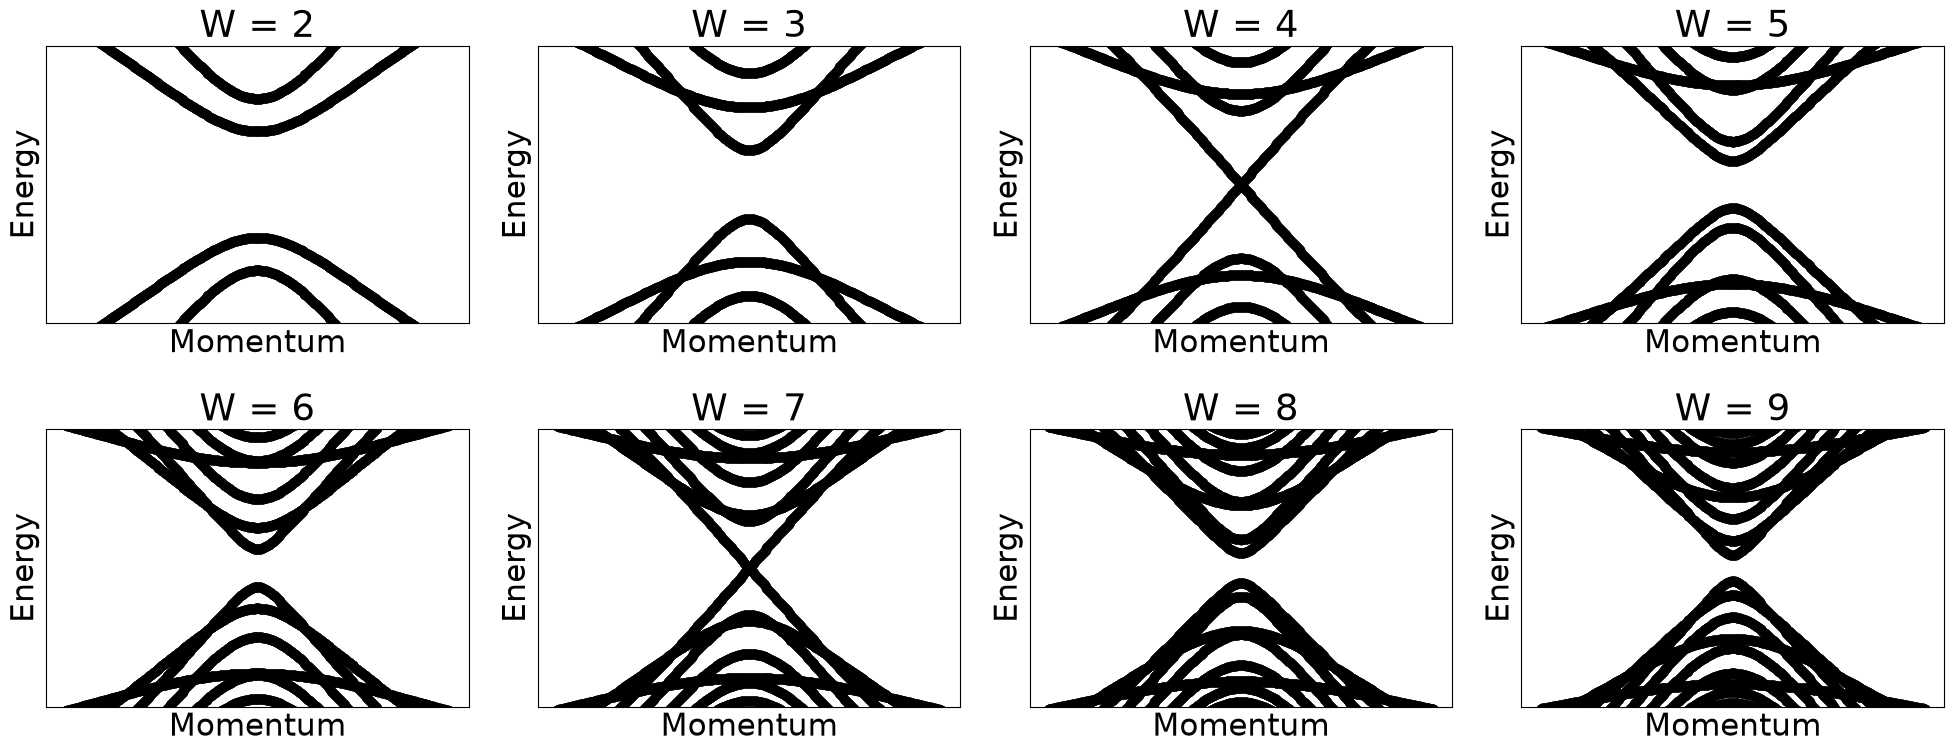

In [14]:
from pyqula import geometry
# plot the bands for different widths
ns = range(2,10,1) # widths
ij = 0 # counter
for n in ns: # loop over widths
    g = geometry.honeycomb_armchair_ribbon(n) # generate ribbon
    h = g.get_hamiltonian() # get the Hamiltonian
    (k,e) = h.get_bands(kpath=["M","G","M"]) # compute the bands
    plt.subplot(len(ns)//4,4,ij+1) ; ij +=1 
    plt.scatter(k,e,c="black") ;  plt.ylim([-1,1]) ; plt.title("W = "+str(n)) # plot
    plt.xticks([]) ; plt.yticks([]) ; plt.xlabel("Momentum") ; plt.ylabel("Energy")
plt.tight_layout()

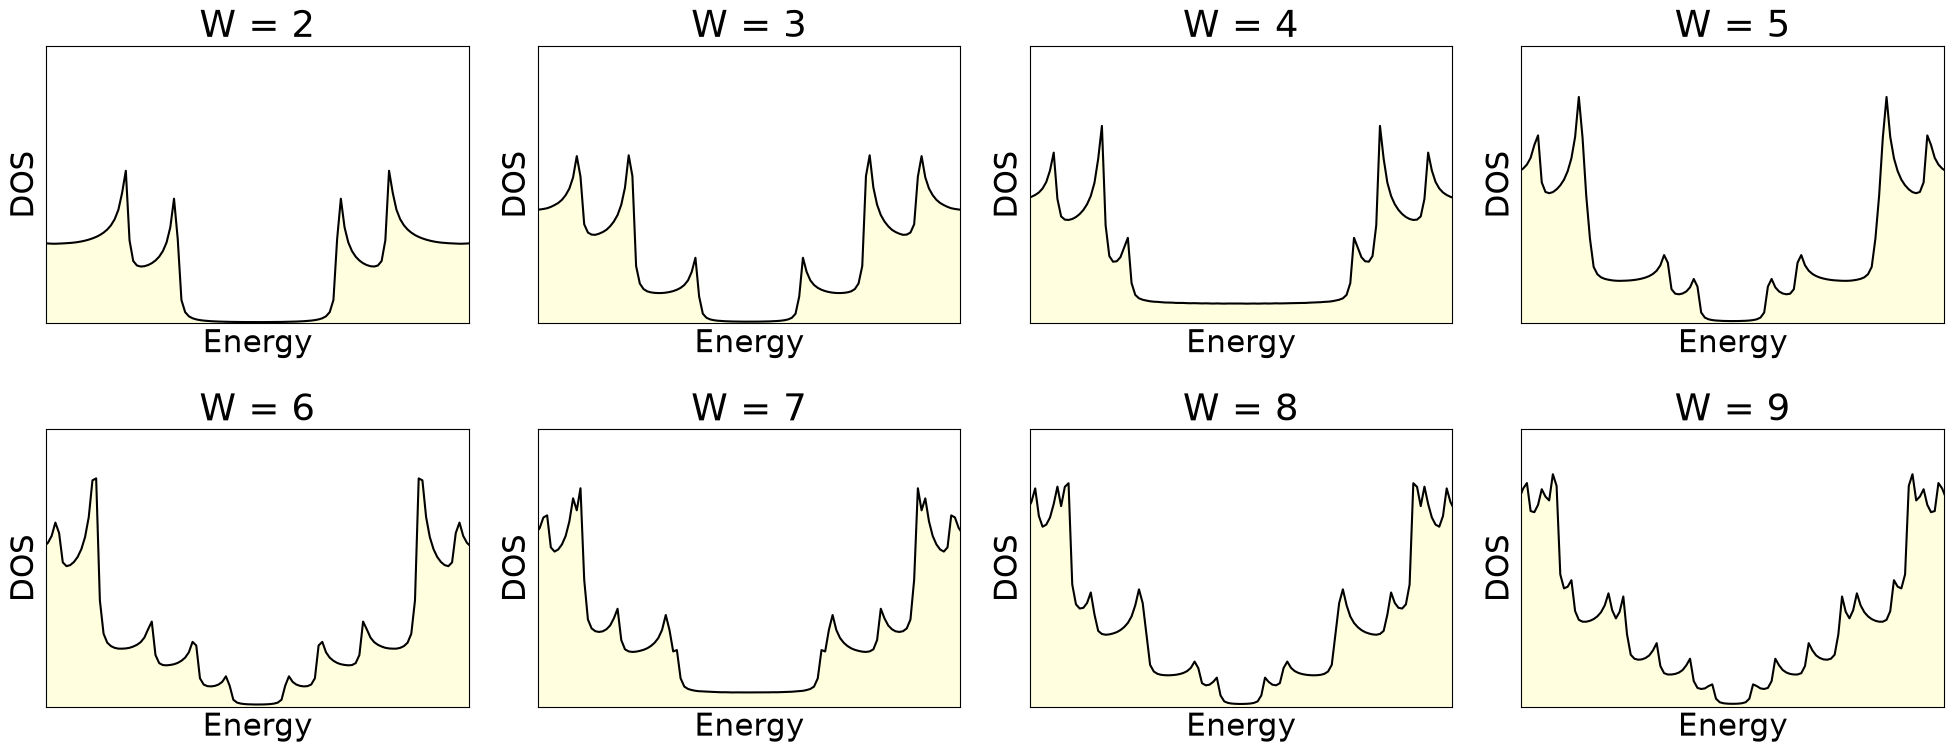

In [15]:
from pyqula import geometry
# plot the DOS for different widths
ns = range(2,10,1) # widths
ij = 0 # counter
for n in ns: # loop over widths
    g = geometry.honeycomb_armchair_ribbon(n) # generate ribbon
    h = g.get_hamiltonian() # get the Hamiltonian
    (e,d) = h.get_dos(delta=1e-2,energies=np.linspace(-3.5,3.5,400),nk=300) # DOS
    plt.subplot(len(ns)//4,4,ij+1) ; ij +=1 
    plt.plot(e,d,c="black") ;  plt.xlim([-1,1]) ; plt.ylim([0,max(d)]) ; plt.title("W = "+str(n)) 
    plt.xticks([]) ; plt.yticks([]) ; plt.xlabel("Energy") ; plt.ylabel("DOS")
    plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') # add a background
plt.tight_layout()

### Exercise
- Some of the nanoribbons are gapless whereas others are gapped. Can you infer which ones are gapless?
- The gap in the gapped nanoribbons decreases with the width. Can you infer what is the functional form of the gap as a function of the width, and why?

#### In the lab
- Perfect graphene armchair nanoribbons can be synthesized with on surface synthesis as shown in
https://pubs.acs.org/doi/full/10.1021/acsnano.6b06405

# Band structures and interactions (***Core***)
Here we will show how electronic interactions can impact a electronic structure, by addressing some interacting models at the mean-field level

As in session 1, the Hubbard interaction $U n_{i\uparrow}n_{i\downarrow}$ is treated at the mean-field level, self-consistently replaced by an effective single-particle potential that depends on the local magnetization $\langle S_z\rangle_i$; here we apply this to 2D honeycomb systems instead of 1D chains.

## Phase transition with electronic interactions
We will first address the impact of electronic repulsion in the honeycomb lattice, showing how at a critical value an interaction induced gap emerges

As in the interacting honeycomb lattice of session 1, the vanishing density of states at the Dirac point means a finite critical interaction $U_c$ is required before the self-consistent order parameter turns on and a gap opens; below $U_c$ the semimetallic Dirac cones survive unperturbed.

([], [])

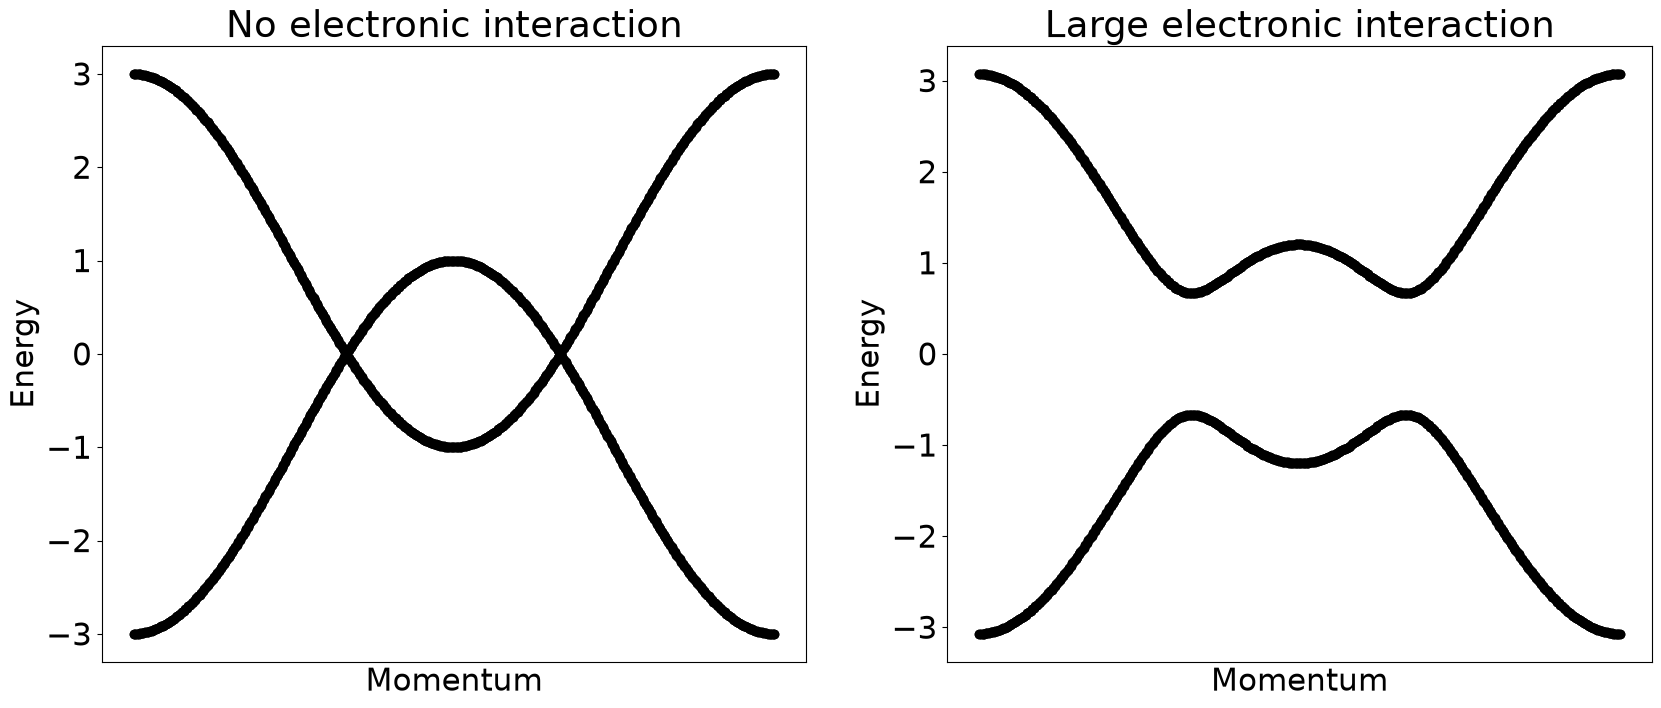

In [16]:
# first plot the mean-field Hamiltonian with no interactions
from pyqula import geometry
g = geometry.honeycomb_lattice() # create a honeycomb lattice
h = g.get_hamiltonian() # generate a Hamiltonian

plt.subplot(1,2,1) ;  plt.title("No electronic interaction")
hscf = h.get_mean_field_hamiltonian(U=0.0,filling=0.5,mf="random",mix=0.9) # solve mean-field Hamiltonian
(k,e) = hscf.get_bands() # get bandstructure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) # plot

# now include a finite interaction U=3
plt.subplot(1,2,2) ;  plt.title("Large electronic interaction")
hscf = h.get_mean_field_hamiltonian(U=3.0,filling=0.5,mf="random",mix=0.9) # solve mean-field Hamiltonian
(k,e) = hscf.get_bands() # get bandstructure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) # plot

### Exercise
- Decrease the value of the onsite interaction U below 2. What happens and why?

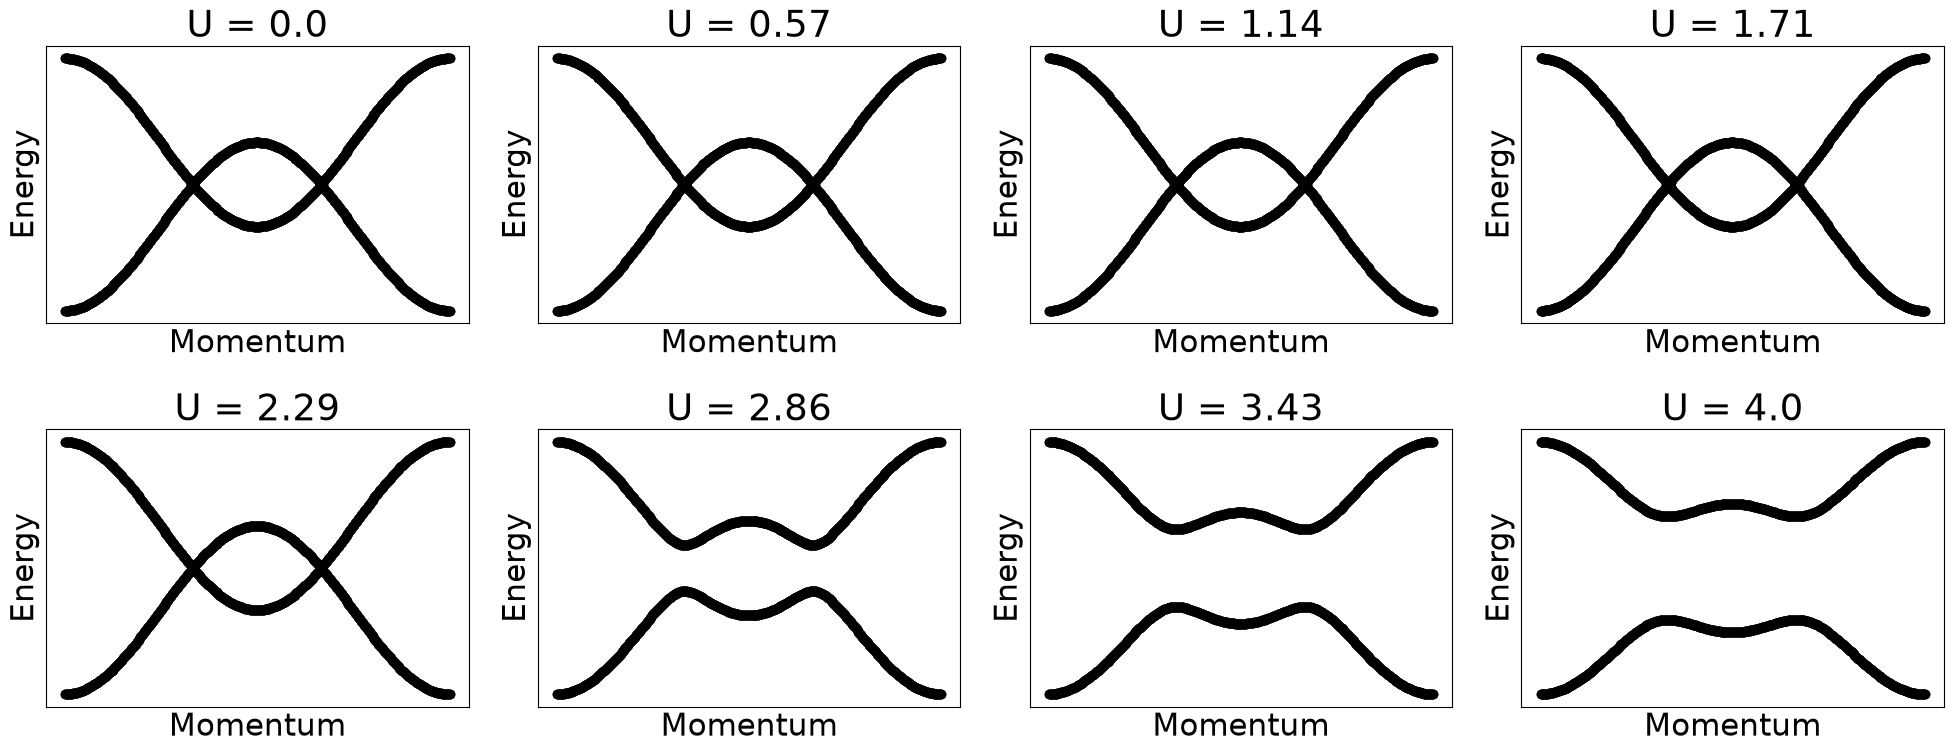

In [17]:
from pyqula import geometry
g = geometry.honeycomb_lattice() # create a honeycomb lattice
# We will solve a Hubbard model at the mean-field level
Us = np.linspace(0.,4.0,8) # Hubbard Us considered
iu = 0 # start counter
for U in Us:
    h = g.get_hamiltonian() # generate a Hamiltonian
    hscf = h.get_mean_field_hamiltonian(U=U, filling=0.5,mf="random",mix=0.9) # solve mean-field Hamiltonian
    (k,e) = hscf.get_bands() # get bandstructure
    plt.subplot(len(Us)//4,4,iu+1) ; iu +=1  # create a subplot
    plt.scatter(k,e,c="black") ;  plt.title("U = "+str(round(U,2)))
    plt.xticks([]) ; plt.yticks([]) ; plt.xlabel("Momentum") ; plt.ylabel("Energy")
plt.tight_layout()

### Exercise
- Find the critical value of U that gives rise to the gap opening
- What is the symmetry breaking that gives rise to such a gap opening?

## Interaction induced symmetry breaking in nanoribbons (***Challenge***)
We will now show that magnetic order can also appear at the edges of a graphene nanoribbon for a zigzag interface

The flat band of zigzag edge states sits exactly at $E=0$ with a large, near-divergent density of states there, so even a modest Hubbard $U$ satisfies the Stoner criterion $Ug(E_F)>1$ locally at the edges — producing a spontaneous magnetic moment confined to the two edges, typically antiferromagnetically coupled to each other rather than appearing in the bulk.

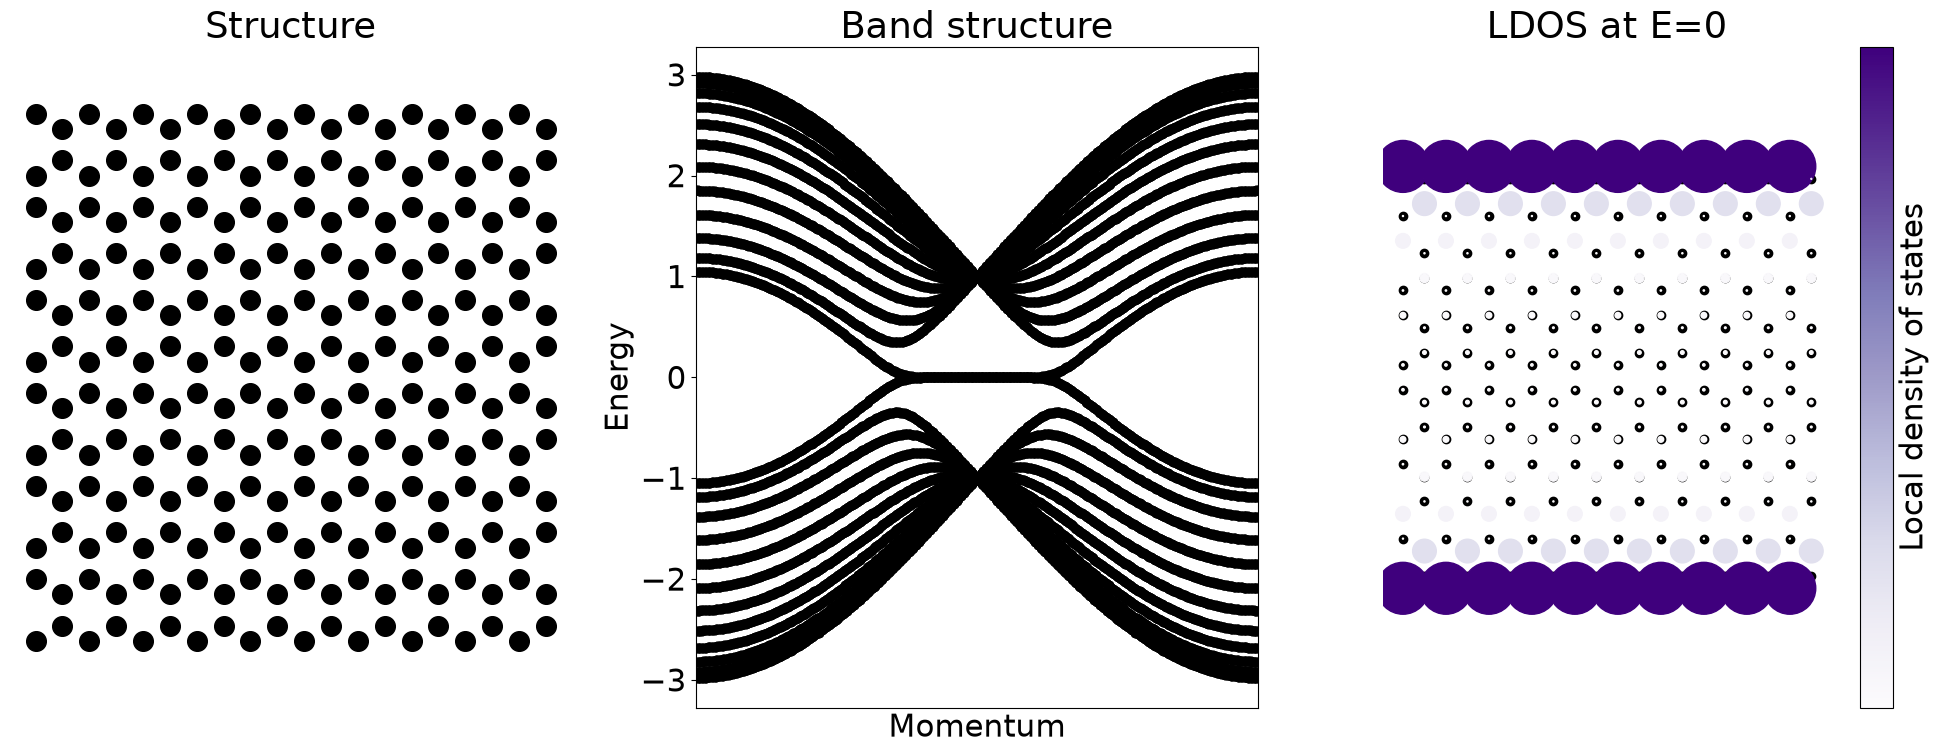

In [18]:
# create a zigzag nanoribbon
from pyqula import geometry
g = geometry.honeycomb_zigzag_ribbon(6) # generate a zigzag nanoribbon
gs = g.get_supercell(10) # make a supercell and plot the structure

plt.subplot(1,3,1) ; plt.title("Structure")
plt.scatter(gs.r[:,0],gs.r[:,1],c="black",s=200) ; plt.axis("equal") ; plt.axis("off") 

# now compute the band structure
plt.subplot(1,3,2) ; plt.title("Band structure")
h = g.get_hamiltonian() # generate the Hamiltonian
(k,e) = h.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
plt.xticks([]) ; plt.xlim([min(k),max(k)])

# now compute the LDOS at E=0
plt.subplot(1,3,3) ; plt.title("LDOS at E=0")
x,y,d = h.get_ldos(e=0.0,delta=1e-2,nrep=10) # get the LDOS
plt.scatter(x,y,c="black") # plot lattice as a reference
plt.scatter(x,y,c=d,s=np.array(d)*100,cmap="Purples") ; plt.axis("off") ; plt.axis("equal") # plot LDOS
# see that the zero modes are located at the edge
plt.colorbar(label="Local density of states",ticks=[])
plt.tight_layout()

### Exercise
- Where are the states of the flat band located?
- When interactions are included at half filling, which states are likely to be affected the most?

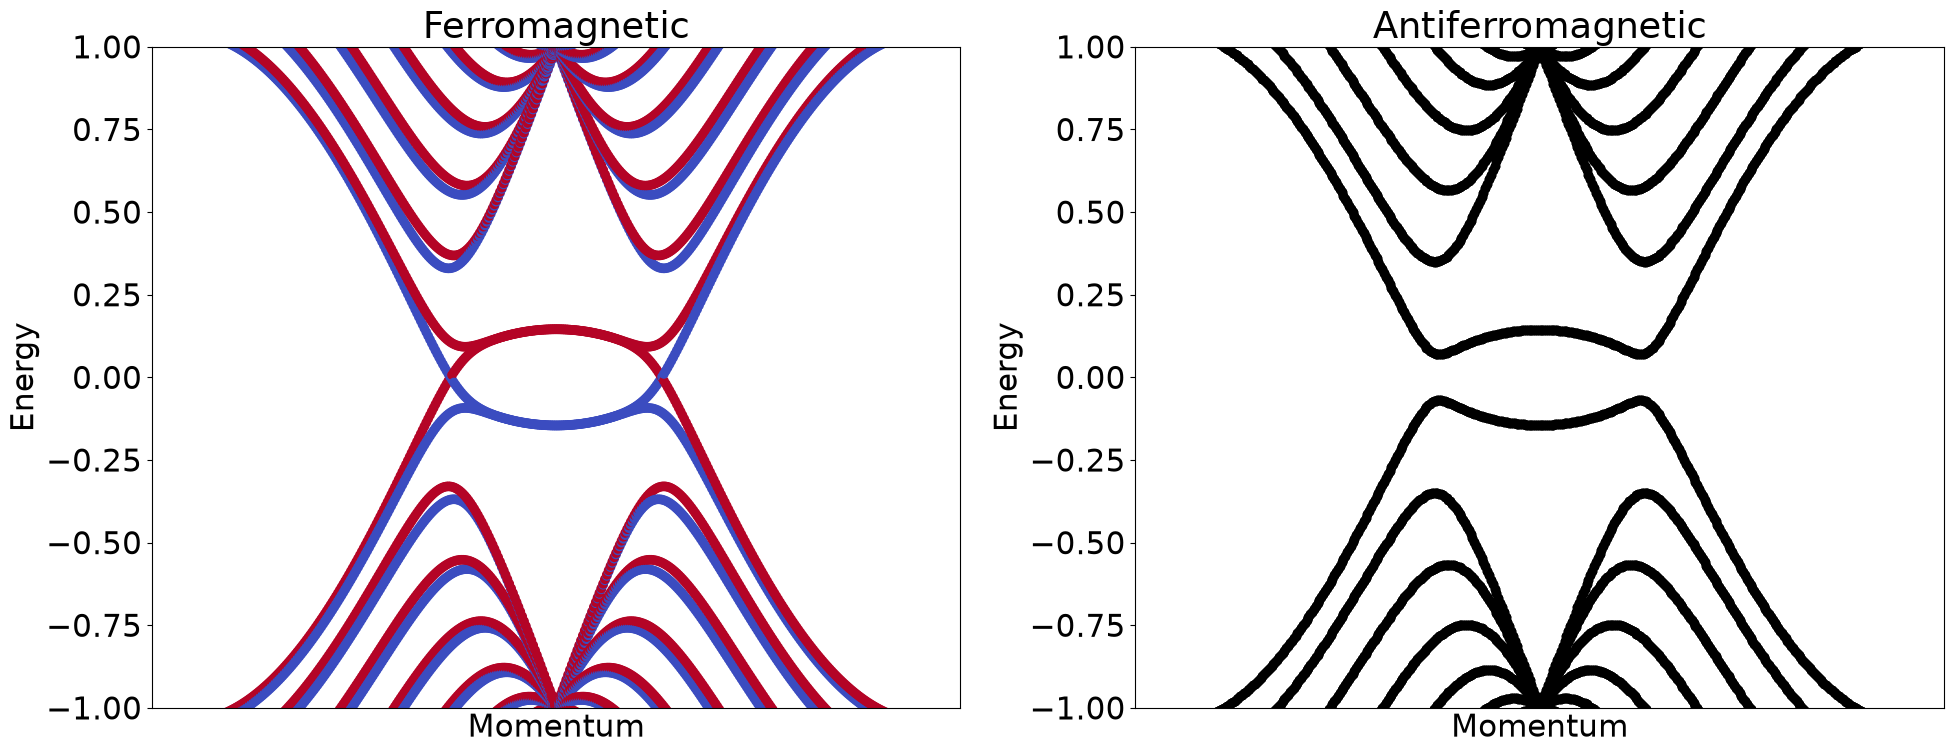

In [19]:
from pyqula import geometry
g = geometry.honeycomb_zigzag_ribbon(6) # generate a zigzag nanoribbon
h = g.get_hamiltonian() # generate the Hamiltonian

# now let us add interactions
# first with ferromagnetic initialization
plt.subplot(1,2,1)
hscf = h.get_mean_field_hamiltonian(U=1.0, filling=0.5,mf="ferro",mix=0.9) # solve mean-field Hamiltonian
(k,e,sz) = hscf.get_bands(operator="sz") # get the eigenenergies
plt.scatter(k,e,c=sz) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.ylim([-1.,1.]) ; plt.xticks([])
plt.title("Ferromagnetic")

# and later with antiferromagnetic initialization
plt.subplot(1,2,2)
hscf = h.get_mean_field_hamiltonian(U=1.0, filling=0.5,mf="antiferro",mix=0.9) # solve mean-field Hamiltonian
(k,e) = hscf.get_bands() # get the eigenenergies
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.ylim([-1.,1.]) ; plt.xticks([]) 
plt.title("Antiferromagnetic")
# note that there is now a splitting between the zero modes

plt.tight_layout()

### Exercise
- We obtained two selfconsistent solutions, one ferromagnetic and one antiferromagnetic, which one do you think that it is the ground state and why?

#### In the lab
- Zigzag graphene nanoribbons featuring edge states can be synthesized using on-surface synthesis, showing the correlated states noted above
https://www.nature.com/articles/nature17151

## Unfolding band structures of a chain with impurities (***Core***)
Let us now see how anticrossings appear when a super-lattice of impurities is included in a tight-binding chain

Unfolding projects the supercell eigenstates back onto the original Brillouin zone via the spectral weight $A(\mathbf k,E)=\sum_n |\langle \mathbf k|\psi_n\rangle|^2\,\delta(E-E_n)$. Without an impurity this simply recovers the original band; a periodic impurity potential couples the folded replicas and opens anticrossings (minigaps) where they would otherwise cross.

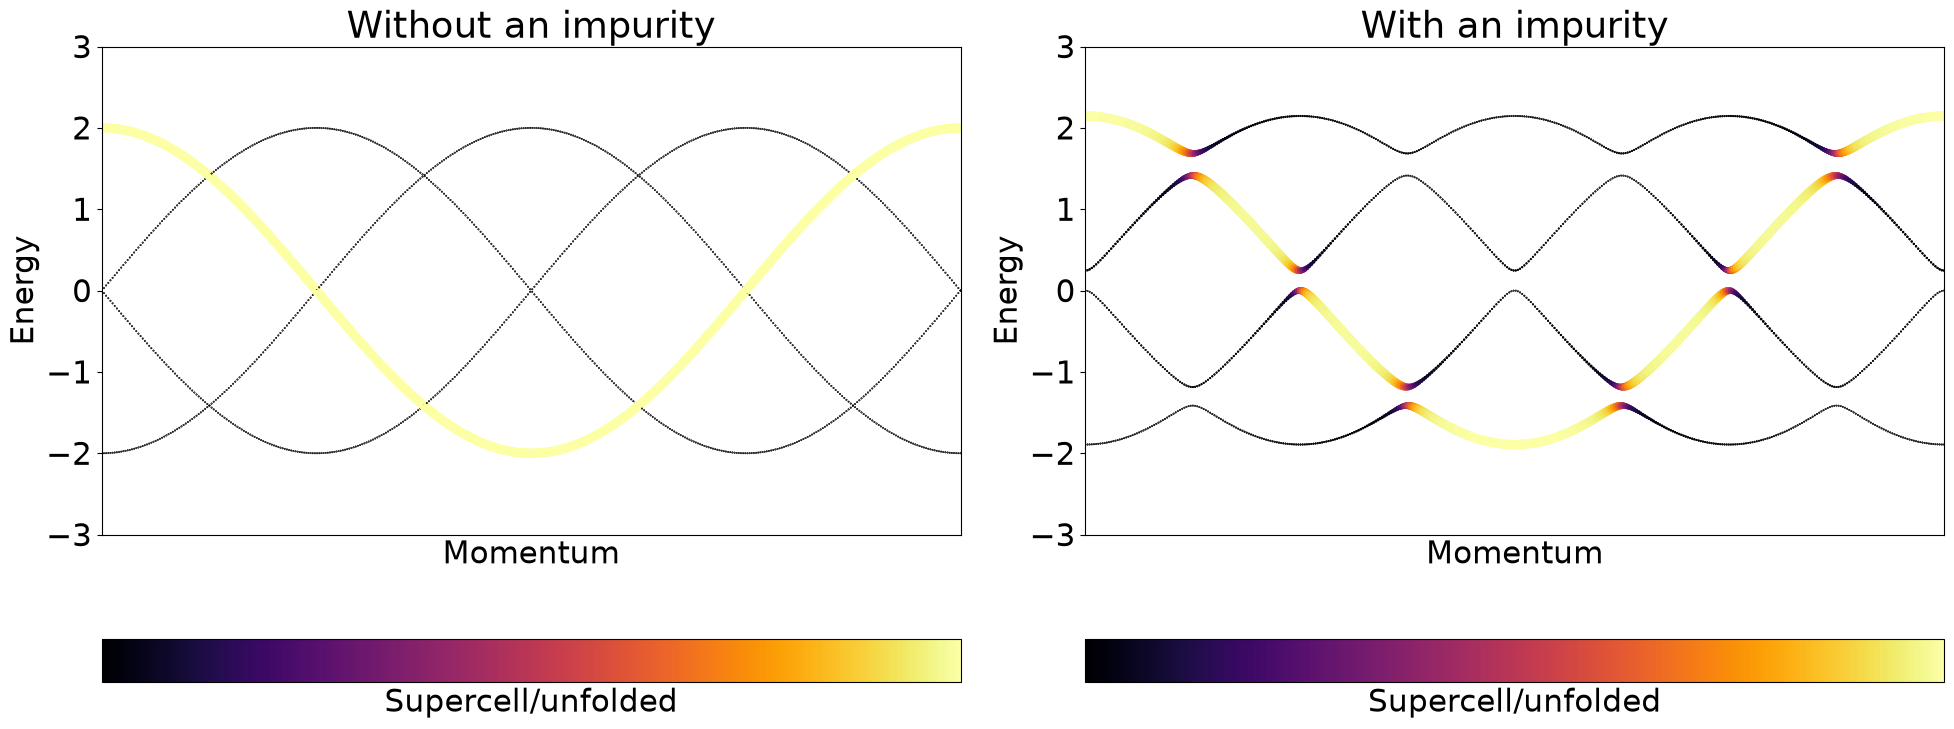

In [20]:
from pyqula import geometry, potentials
g = geometry.chain() # take chain geometry
#g = geometry.ladder() # take ladder geometry
N = 4 # size of the supercell
g = g.get_supercell(N,store_primal=True) # generate a supercell
h = g.get_hamiltonian() # generate Hamiltonian

kpath = g.get_kpath()*N # compute in the original Brillouin zone, just by extending the reciprocal vectors

def plot_case(h):
    (k,e,c) = h.get_bands(operator="unfold",kpath=kpath) # compute band structure (unfolding to the original cell)
    plt.scatter(k,e,c=c,s=c*8+.1,cmap="inferno") ; plt.xlabel("Momentum") 
    plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-3.,3.])# plot
    plt.colorbar(label="Supercell/unfolded",ticks=[],orientation="horizontal")
    plt.xlim([min(k),max(k)])

# first without impurity
plt.subplot(1,2,1) ; plt.title("Without an impurity")
plot_case(h)


# now with an impurity
V = 0.5 # strength of the impurity
h.add_onsite(potentials.impurity(g.r[0],v=V)) # cell with an impurity
plt.subplot(1,2,2) ; plt.title("With an impurity")
plot_case(h)

plt.tight_layout()

### Exercise
- Recompute the band structure above for other supercell sizes. What do you observe and why?
- Take a very large value for the impurity potential $V$ ($V=10$ for example). What happens to the band structure?
- Replace the chain for a ladder, and choose a large impurity $V$. What do you observe, and why is it different than the chain?

## Breaking translational symmetry: Impurities in graphene (***Challenge***)
Let us now look at the effect of vacancies in graphene. An impurity can be modeled as an infinite potential

A vacancy is modeled by sending the onsite energy of one site to $V\to\infty$, removing that site from the low-energy Hilbert space. Because it unbalances the two honeycomb sublattices by one site, it pins a quasi-localized zero-energy resonance at the Dirac point, visible as a sharp peak in the DOS at $E=0$.

(0.0, 1.429715644661327)

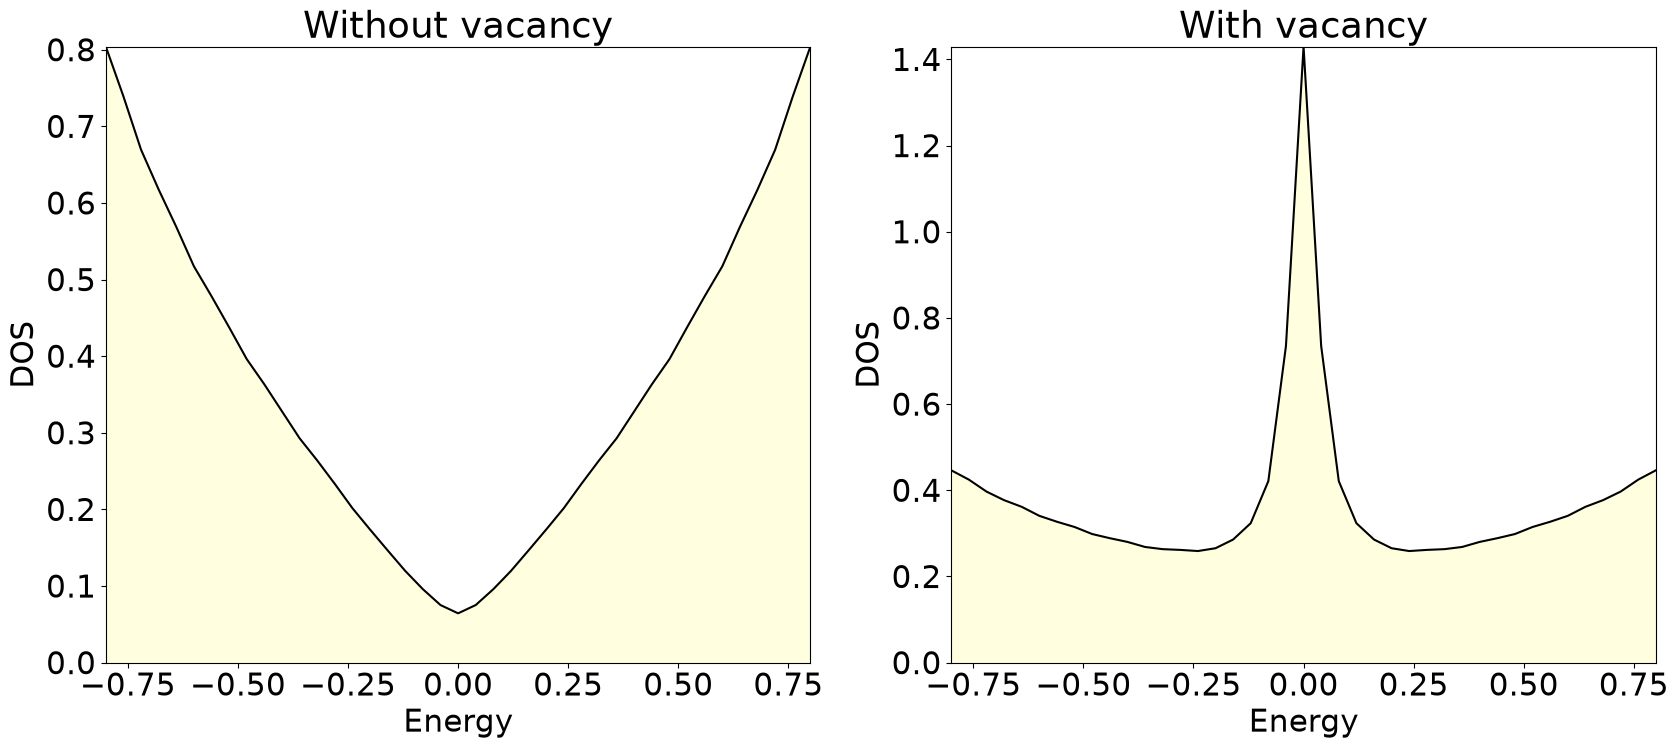

In [21]:
from pyqula import geometry, embedding, potentials
g = geometry.honeycomb_lattice() # take a honeycomb lattice
h = g.get_hamiltonian() # generate Hamiltonian

hv = h.copy() # make a copy
hv.add_onsite(potentials.impurity(g.r[0],v=1e6)) # unit cell with a vacancy
# first the pristine
plt.subplot(1,2,1) ; plt.title("Without vacancy")
eb = embedding.Embedding(h,m=h) 
energies = np.linspace(-.8,.8,41) # energy grid
(e,d) = eb.multidos(energies=energies,delta=3e-2) # compute DOS
plt.plot(e,d,c="black") ; plt.xlabel("Energy") ; plt.ylabel("DOS") # plot
plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') # add a background
plt.xlim([min(e),max(e)]) ; plt.ylim([0.,max(d)])

# create an embedding object (infinite pristine system with h, central impurity hv)
plt.subplot(1,2,2) ; plt.title("With vacancy")
eb = embedding.Embedding(h,m=hv) 
#d = [eb.get_dos(e=e,delta=3e-2) for e in energies]
(e,d) = eb.multidos(energies=energies,delta=3e-2) # compute DOS
plt.plot(e,d,c="black") ; plt.xlabel("Energy") ; plt.ylabel("DOS") # plot
plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') # add a background
plt.xlim([min(e),max(e)]) ; plt.ylim([0.,max(d)])

### Exercise
- Replace the vacancy by just a large finite potential (10 for example). How does the DOS of the impurity case change?
- In the case above, what happens if you change the sign of the local potential?

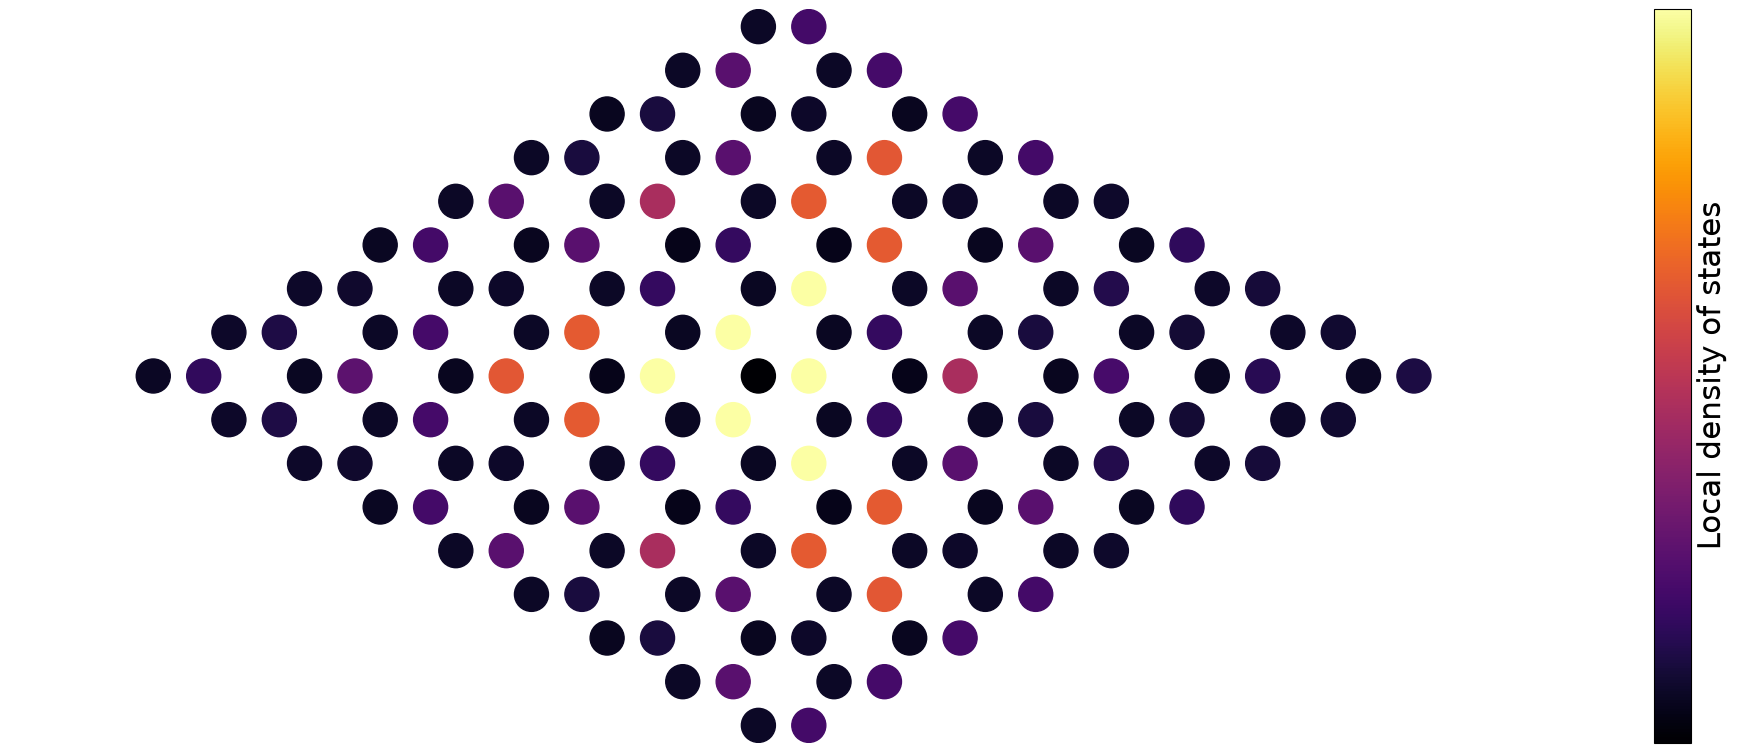

In [22]:
from pyqula import geometry, embedding, potentials
g = geometry.honeycomb_lattice() # take a honeycomb lattice
h = g.get_hamiltonian() # generate Hamiltonian
hv = h.copy() # make a copy
hv.add_onsite(potentials.impurity(g.r[0],v=1e6)) # unit cell with a vacancy
eb = embedding.Embedding(h,m=hv) # create the embedding object
(x,y,d) = eb.get_ldos(nsuper=9,energy=0.,delta=3e-2) # compute LDOS
d = d/np.max(d) # normalize
plt.scatter(x,y,c=d,s=600,vmin=0.,vmax=0.3,cmap="inferno") ; plt.axis("off") ; plt.axis("equal")
plt.colorbar(label="Local density of states",ticks=[])
plt.tight_layout()

### Exercise
- Change the energy for the LDOS. How does the profile change, and how do you interpret it?
- Replace the infinite potential by a finite potential (10 for example). How does the profile change?

#### In the lab
- Zero modes created by creating hydrogen atoms in graphene can be controllably engineered with STM
https://www.science.org/doi/full/10.1126/science.aad8038

## Unfolding vacancies in a graphene superlattice (***Challenge***)
Let us now see how flat bands appear in a graphene supercell when impurities are included

A periodic superlattice of vacancies couples their individual zero-energy resonances into a dispersionless impurity band pinned near $E=0$ — visible in the unfolded spectrum as a flat, weakly-dispersing feature distinct from the folded bulk bands.

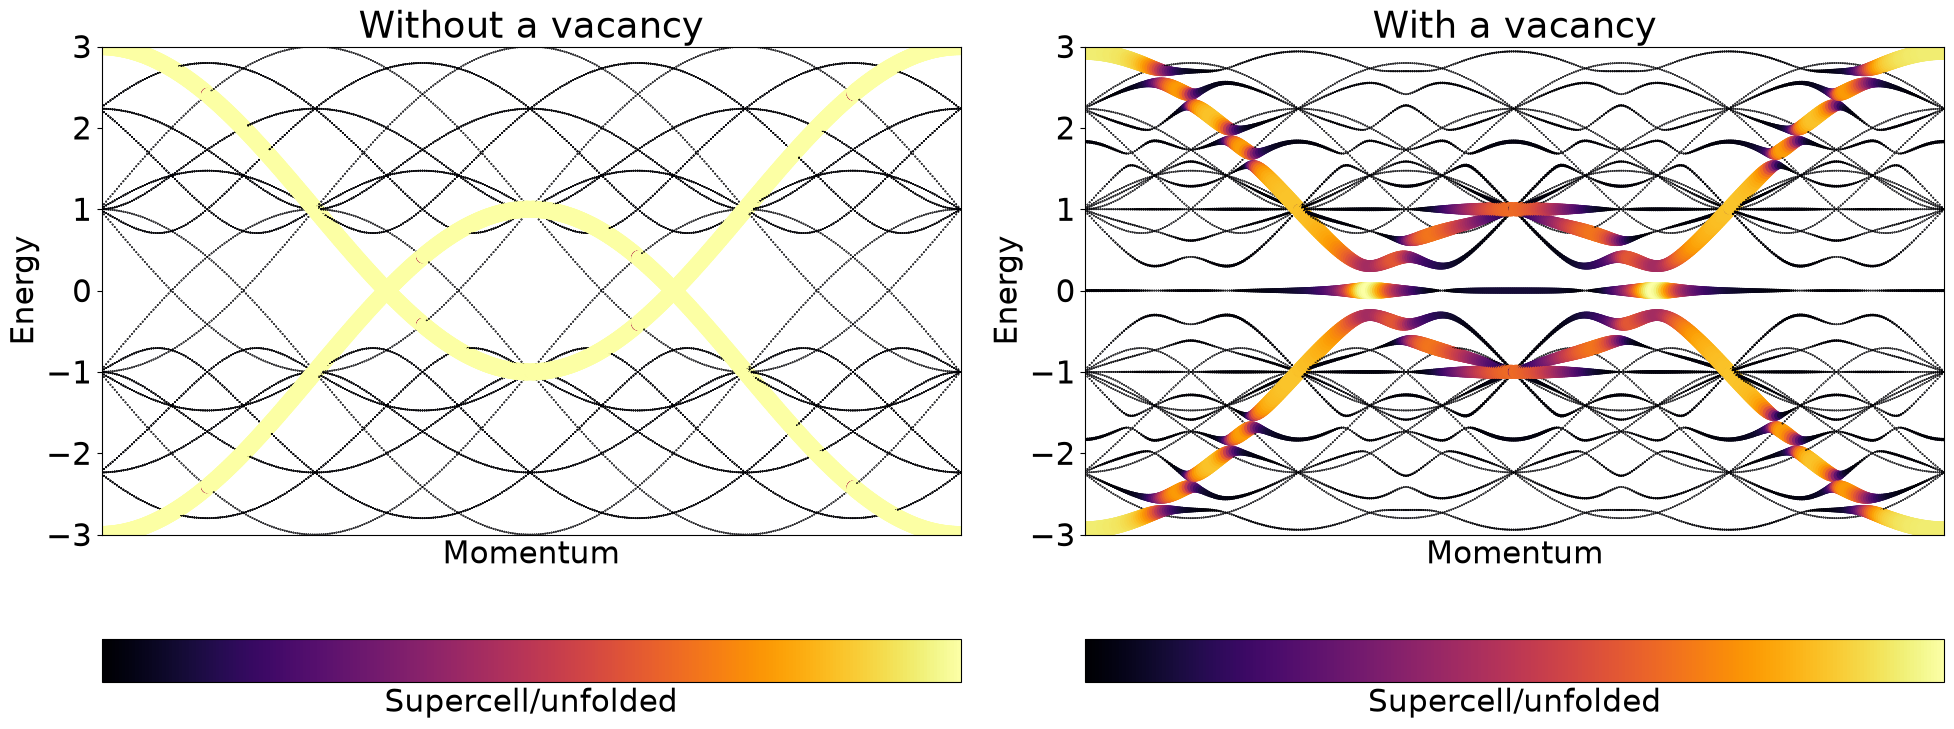

In [23]:
from pyqula import geometry, potentials
g = geometry.honeycomb_lattice() # take a honeycomb lattice
N = 4 # size of the supercell
g = g.get_supercell((N,N),store_primal=True) # generate a supercell
h = g.get_hamiltonian() # generate Hamiltonian

kpath = g.get_kpath()*N # compute in the original Brillouin zone, just by extending the reciprocal vectors

def plot_case(h):
    (k,e,c) = h.get_bands(operator="unfold",kpath=kpath) # compute band structure (unfolding to the original cell)
    plt.scatter(k,e,c=c,s=c*8+.1,cmap="inferno") ; plt.xlabel("Momentum") 
    plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-3.,3.])# plot
    plt.colorbar(label="Supercell/unfolded",ticks=[],orientation="horizontal")
    plt.xlim([min(k),max(k)])

# first without impurity
plt.subplot(1,2,1) ; plt.title("Without a vacancy")
plot_case(h)


# now with an impurity
h.add_onsite(potentials.impurity(g.r[0],v=1e6)) # cell with a vacancy
plt.subplot(1,2,2) ; plt.title("With a vacancy")
plot_case(h)

plt.tight_layout()

### Exercise
- Recompute the band structure above for other supercell sizes. Do you observe the flat band for all the cases?
- Take a large finite value for the impurity potential (10 for example). What happens to the flat band?